# Startup Investment EDA


## 1. Imports


In [16]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown


## 2. Data loading


In [17]:
from pathlib import Path

# Load the CSV tables stored in this project's data folder.
data_dir = Path.cwd() / "data"
if not data_dir.is_dir():
    raise FileNotFoundError(f"Data folder not found: {data_dir.resolve()}")

csv_files = sorted(data_dir.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {data_dir.resolve()}")

dfs = {file.name: pd.read_csv(file, low_memory=False) for file in csv_files}
if "objects.csv" not in dfs:
    raise FileNotFoundError(f"Expected objects.csv in {data_dir.resolve()}")

# Keep each source CSV as its own DataFrame; df/obj refer to the objects table.
df = dfs["objects.csv"]
obj = df
print(f"Loaded {len(dfs)} CSV tables; objects.csv has {df.shape[0]:,} rows and {df.shape[1]} columns.")

Loaded 11 CSV tables; objects.csv has 462,651 rows and 40 columns.


## 3. Dataset overview


In [18]:
print("objects.csv columns:")
display(df.columns.to_list())

objects.csv columns:


['id',
 'entity_type',
 'entity_id',
 'parent_id',
 'name',
 'normalized_name',
 'permalink',
 'category_code',
 'status',
 'founded_at',
 'closed_at',
 'domain',
 'homepage_url',
 'twitter_username',
 'logo_url',
 'logo_width',
 'logo_height',
 'short_description',
 'description',
 'overview',
 'tag_list',
 'country_code',
 'state_code',
 'city',
 'region',
 'first_investment_at',
 'last_investment_at',
 'investment_rounds',
 'invested_companies',
 'first_funding_at',
 'last_funding_at',
 'funding_rounds',
 'funding_total_usd',
 'first_milestone_at',
 'last_milestone_at',
 'milestones',
 'relationships',
 'created_by',
 'created_at',
 'updated_at']

In [19]:
for table_name, frame in dfs.items():
    print(f"{table_name}: {frame.shape[0]:,} rows x {frame.shape[1]} columns")
    display(frame.head(3))


acquisitions.csv: 9,562 rows x 12 columns


,id,acquisition_id,acquiring_object_id,acquired_object_id,term_code,price_amount,price_currency_code,acquired_at,source_url,source_description,created_at,updated_at
0,1,1,c:11,c:10,NaN,20000000.0,USD,2007-05-30,http://venturebeat.com/2007/05/30/fox-interact...,Fox Interactive confirms purchase of Photobuck...,2007-05-31 22:19:54,2008-05-21 19:23:44
1,2,7,c:59,c:72,cash,60000000.0,USD,2007-07-01,http://www.techcrunch.com/2007/07/02/deal-is-c...,Deal is Confirmed: Google Acquired GrandCentral,2007-07-03 08:14:50,2011-05-06 21:51:05
2,3,8,c:24,c:132,cash,280000000.0,USD,2007-05-01,http://www.techcrunch.com/2007/05/30/cbs-acqui...,CBS Acquires Europeâs Last.fm for $280 million,2007-07-12 04:19:24,2008-05-19 04:48:50


degrees.csv: 109,610 rows x 8 columns


,id,object_id,degree_type,subject,institution,graduated_at,created_at,updated_at
0,1,p:6117,MBA,NaN,NaN,NaN,2008-02-19 03:17:36,2008-02-19 03:17:36
1,2,p:6136,BA,"English, French","Washington University, St. Louis",1990-01-01,2008-02-19 17:58:31,2008-02-25 00:23:55
2,3,p:6136,MS,Mass Communication,Boston University,1992-01-01,2008-02-19 17:58:31,2008-02-25 00:23:55


funding_rounds.csv: 52,928 rows x 23 columns


...

,id,object_id,office_id,description,region,address1,address2,city,zip_code,state_code,country_code,latitude,longitude,created_at,updated_at
0,1,c:1,1,NaN,Seattle,710 - 2nd Avenue,Suite 1100,Seattle,98104,WA,USA,47.603122,-122.333253,NaN,NaN
1,2,c:3,3,Headquarters,SF Bay,4900 Hopyard Rd,Suite 310,Pleasanton,94588,CA,USA,37.692934,-121.904945,NaN,NaN
2,3,c:4,4,NaN,SF Bay,135 Mississippi St,NaN,San Francisco,94107,CA,USA,37.764726,-122.394523,NaN,NaN


people.csv: 226,709 rows x 6 columns


,id,object_id,first_name,last_name,birthplace,affiliation_name
0,1,p:2,Ben,Elowitz,NaN,Blue Nile
1,2,p:3,Kevin,Flaherty,NaN,Wetpaint
2,3,p:4,Raju,Vegesna,NaN,Zoho


relationships.csv: 402,878 rows x 11 columns


,id,relationship_id,person_object_id,relationship_object_id,start_at,end_at,is_past,sequence,title,created_at,updated_at
0,1,1,p:2,c:1,NaN,NaN,0,8,Co-Founder/CEO/Board of Directors,2007-05-25 07:03:54,2013-06-03 09:58:46
1,2,2,p:3,c:1,NaN,NaN,1,279242,VP Marketing,2007-05-25 07:04:16,2010-05-21 16:31:34
2,3,3,p:4,c:3,NaN,NaN,0,4,Evangelist,2007-05-25 19:33:03,2013-06-29 13:36:58


## 4. Analysis overview

Related CSV tables are analyzed separately. Source data is not modified, and no target is assumed.


In [20]:
sns.set_theme(style="whitegrid", context="notebook")

if "dfs" not in globals() or not isinstance(dfs, dict) or not dfs:
    raise RuntimeError("Expected the existing CSV loader to create a non-empty `dfs` dictionary.")

# These are references for analysis only; all transformations below create temporary results.
analysis_frames = {name: frame for name, frame in dfs.items() if isinstance(frame, pd.DataFrame)}
if not analysis_frames:
    raise RuntimeError("No pandas DataFrames were found in `dfs`.")

text_name_hints = ("description", "overview", "url", "address", "permalink", "twitter", "tag_list")

def _eda_role(column, series):
    name = str(column).strip().lower()
    if re.search(r"(^id$|_id$)", name):
        return "identifier"
    if re.search(r"(_at$|_date$|_time$|^date$|^time$)", name):
        return "datetime-like"
    if pd.api.types.is_bool_dtype(series.dtype):
        return "Boolean"
    if pd.api.types.is_numeric_dtype(series.dtype):
        unique_values = series.dropna().unique() if series.nunique(dropna=True) <= 2 else []
        if 0 < len(unique_values) <= 2 and set(unique_values).issubset({0, 1, False, True}):
            return "binary numeric"
        return "numerical"
    if pd.api.types.is_object_dtype(series.dtype) or pd.api.types.is_string_dtype(series.dtype) or pd.api.types.is_categorical_dtype(series.dtype):
        nonmissing = int(series.notna().sum())
        unique_count = int(series.nunique(dropna=True))
        if any(hint in name for hint in text_name_hints) or unique_count > max(100, int(nonmissing * 0.05)):
            return "text / high-cardinality"
        return "categorical"
    return "other / mixed"

def _meaning_hint(column, series, role):
    name = str(column).strip().lower()
    known = {
        "id": "Row/entity identifier; not a measurement.",
        "entity_id": "Numeric identifier associated with an entity; verify its key mapping.",
        "object_id": "Entity reference/foreign key, inferred from the naming convention.",
        "entity_type": "Recorded kind of entity (for example, Company or Person).",
        "status": "Recorded lifecycle/status label; not necessarily a future outcome.",
        "category_code": "Industry/category label; exact taxonomy needs source documentation.",
        "funding_round_type": "Recorded type of funding round.",
        "funding_round_code": "Recorded round-stage/code; exact semantics need source documentation.",
        "funded_at": "Date associated with the funding event.",
        "founded_at": "Recorded company founding date.",
        "closed_at": "Recorded closure date; likely missing for entities without a closure record.",
        "acquired_at": "Date associated with the acquisition event.",
        "public_at": "Date associated with the IPO/public listing event.",
        "milestone_at": "Date associated with the milestone event.",
        "funding_total_usd": "Recorded aggregate funding amount in USD; aggregation definition needs confirmation.",
        "raised_amount_usd": "Funding amount expressed in USD, inferred from the field name.",
        "pre_money_valuation_usd": "Pre-money valuation expressed in USD, inferred from the field name.",
        "post_money_valuation_usd": "Post-money valuation expressed in USD, inferred from the field name.",
        "latitude": "Geographic latitude coordinate.",
        "longitude": "Geographic longitude coordinate.",
        "participants": "Recorded participant count for the funding round.",
        "is_first_round": "Binary indicator that the round is marked as first.",
        "is_last_round": "Binary indicator that the round is marked as last.",
        "is_past": "Binary indicator that the relationship is marked as past.",
        "created_at": "Record creation timestamp, inferred from the field name.",
        "updated_at": "Record update timestamp, inferred from the field name."
    }
    if name in known:
        return known[name]
    if name.endswith("_currency_code"):
        return "Currency code associated with a financial amount; confirm whether values are standardized."
    if name.endswith("_usd"):
        return "Financial quantity expressed in USD, inferred from the field name; exact definition needs confirmation."
    if name.endswith(("_at", "_date", "_time")):
        return "Date/time associated with the named event or record; confirm exact semantics and timezone."
    if role == "identifier":
        return "Identifier or relationship key inferred from the field name; not a measurement."
    if role in ("numerical", "binary numeric"):
        return "Numeric measurement/count inferred from the field name; unit and definition need source documentation."
    if role == "categorical":
        return "Categorical label/code; allowed values and taxonomy need source documentation."
    if role == "text / high-cardinality":
        return "Free-text, name, URL, or high-cardinality value; meaning inferred from the field name."
    if role == "Boolean":
        return "Boolean feature; interpretation needs source documentation."
    return "Meaning is unclear from the field name alone; consult the data dictionary."

profile_rows = []
for table_name, frame in analysis_frames.items():
    for column in frame.columns:
        series = frame[column]
        role = _eda_role(column, series)
        examples = [str(value).replace("\n", " ")[:90] for value in series.dropna().head(3).tolist()]
        profile_rows.append({
            "table": table_name, "column": column, "dtype": str(series.dtype), "role": role,
            "rows": len(frame), "missing": int(series.isna().sum()),
            "missing_pct": round(float(series.isna().mean() * 100), 2),
            "unique_non_null": int(series.nunique(dropna=True)), "meaning_hint": _meaning_hint(column, series, role), "example_values": examples
        })

column_profile = pd.DataFrame(profile_rows)
overview_rows = []
for table_name, frame in analysis_frames.items():
    table_profile = column_profile[column_profile["table"] == table_name]
    role_counts = table_profile["role"].value_counts().to_dict()
    overview_rows.append({
        "table": table_name, "rows": len(frame), "columns": len(frame.columns),
        "missing_cells": int(frame.isna().sum().sum()),
        "missing_cells_pct": round(float(frame.isna().to_numpy().mean() * 100), 2),
        "exact_duplicate_rows": int(frame.duplicated().sum()),
        "memory_mb": round(float(frame.memory_usage(index=True, deep=True).sum() / (1024 ** 2)), 1),
        "feature_roles": role_counts
    })
dataset_overview = pd.DataFrame(overview_rows).sort_values("rows", ascending=False).reset_index(drop=True)

print("Dataset overview (each CSV is a separate related table; these are not one flat modeling table):")
display(dataset_overview)
print("Feature profile for every column:")
display(column_profile.sort_values(["table", "column"]).reset_index(drop=True))


Dataset overview (each CSV is a separate related table; these are not one flat modeling table):


,table,rows,columns,missing_cells,missing_cells_pct,exact_duplicate_rows,memory_mb,feature_roles
0,objects.csv,462651,40,7917475,42.78,0,388.1,"{'text / high-cardinality': 13, 'datetime-like..."
1,relationships.csv,402878,11,511067,11.53,0,63.8,"{'identifier': 4, 'datetime-like': 4, 'binary ..."
2,people.csv,226709,6,198663,14.60,0,17.7,"{'text / high-cardinality': 4, 'identifier': 2}"
3,offices.csv,112718,15,431467,25.52,0,19.7,"{'text / high-cardinality': 6, 'identifier': 3..."
4,degrees.csv,109610,8,91144,10.39,0,16.8,"{'text / high-cardinality': 3, 'datetime-like'..."
5,investments.csv,80902,6,0,0.00,0,7.6,"{'identifier': 4, 'datetime-like': 2}"
6,funding_rounds.csv,52928,23,78511,6.45,0,18.6,"{'numerical': 7, 'categorical': 5, 'identifier..."
7,milestones.csv,39456,9,18243,5.14,0,11.5,"{'datetime-like': 3, 'text / high-cardinality'..."
8,acquisitions.csv,9562,12,9658,8.42,0,2.7,"{'identifier': 4, 'datetime-like': 3, 'categor..."
9,funds.csv,1564,11,753,4.38,0,0.4,"{'identifier': 3, 'text / high-cardinality': 3..."


Feature profile for every column:


,table,column,dtype,role,rows,missing,missing_pct,unique_non_null,meaning_hint,example_values
0,acquisitions.csv,acquired_at,str,datetime-like,9562,29,0.30,2642,Date associated with the acquisition event.,"[2007-05-30, 2007-07-01, 2007-05-01]"
1,acquisitions.csv,acquired_object_id,str,identifier,9562,1,0.01,9411,Identifier or relationship key inferred from t...,"[c:10, c:72, c:132]"
2,acquisitions.csv,acquiring_object_id,str,identifier,9562,0,0.00,4872,Identifier or relationship key inferred from t...,"[c:11, c:59, c:24]"
3,acquisitions.csv,acquisition_id,int64,identifier,9562,0,0.00,9562,Identifier or relationship key inferred from t...,"[1, 7, 8]"
4,acquisitions.csv,created_at,str,datetime-like,9562,0,0.00,9293,"Record creation timestamp, inferred from the f...","[2007-05-31 22:19:54, 2007-07-03 08:14:50, 200..."
...,...,...,...,...,...,...,...,...,...,...
149,relationships.csv,relationship_object_id,str,identifier,402878,0,0.00,137289,Identifier or relationship key inferred from t...,"[c:1, c:1, c:3]"
150,relationships.csv,sequence,int64,numerical,402878,0,0.00,5770,Numeric measurement/count inferred from the fi...,"[8, 279242, 4]"
151,relationships.csv,start_at,str,datetime-like,402878,195883,48.62,4778,Date/time associated with the named event or r...,"[2006-03-01, 2005-07-01, 1993-07-04]"
152,relationships.csv,title,str,text / high-cardinality,402878,13352,3.31,92336,"Free-text, name, URL, or high-cardinality valu...","[Co-Founder/CEO/Board of Directors, VP Marketi..."


## 5. Dataset structure and quality

Tables remain separate to preserve their original row grain. Review inferred roles and keys against source documentation.


In [21]:
# Missingness and exact duplicates are reported without dropping anything.
missing_summary = column_profile.loc[column_profile["missing"] > 0, [
    "table", "column", "missing", "missing_pct", "unique_non_null"
]].sort_values(["missing_pct", "missing"], ascending=False).reset_index(drop=True)
print(f"Columns with missing data: {len(missing_summary):,} of {len(column_profile):,}.")
display(missing_summary)

# Check likely table keys, while keeping any repeated-key records in the source tables.
primary_key_candidates = {
    "acquisitions.csv": "acquisition_id", "degrees.csv": "id",
    "funding_rounds.csv": "funding_round_id", "funds.csv": "fund_id",
    "investments.csv": "id", "ipos.csv": "ipo_id", "milestones.csv": "id",
    "objects.csv": "id", "offices.csv": "office_id", "people.csv": "id",
    "relationships.csv": "relationship_id"
}
key_checks = []
for table_name, key in primary_key_candidates.items():
    frame = analysis_frames.get(table_name)
    if frame is not None and key in frame.columns:
        key_checks.append({
            "table": table_name, "candidate_key": key,
            "missing_key_values": int(frame[key].isna().sum()),
            "duplicate_key_rows": int(frame[key].duplicated(keep=False).sum()),
            "unique_key_values": int(frame[key].nunique(dropna=True))
        })
key_quality = pd.DataFrame(key_checks)
print("Candidate primary-key checks (the suggested keys are inferred from field names):")
display(key_quality)

# Flag simple string-format inconsistencies only for manageable categorical columns.
category_quality_rows = []
for row in profile_rows:
    if row["role"] != "categorical":
        continue
    series = analysis_frames[row["table"]][row["column"]].dropna()
    if not (pd.api.types.is_object_dtype(series.dtype) or pd.api.types.is_string_dtype(series.dtype)):
        continue
    values = series.astype("string")
    whitespace_rows = int(values.ne(values.str.strip()).sum())
    normalized_collision_groups = int((values.groupby(values.str.strip().str.casefold()).nunique() > 1).sum())
    if whitespace_rows or normalized_collision_groups:
        category_quality_rows.append({
            "table": row["table"], "column": row["column"],
            "leading_or_trailing_space_rows": whitespace_rows,
            "case_or_space_normalization_collision_groups": normalized_collision_groups
        })
category_quality = pd.DataFrame(category_quality_rows, columns=[
    "table", "column", "leading_or_trailing_space_rows", "case_or_space_normalization_collision_groups"
])
print("Potential categorical formatting inconsistencies (not corrected automatically):")
display(category_quality if not category_quality.empty else pd.DataFrame({"result": ["None detected in the categorical fields checked."]}))
# Test date-like fields for parseability without converting or replacing the source columns.
datetime_quality_rows = []
for row in profile_rows:
    if row["role"] != "datetime-like":
        continue
    values = analysis_frames[row["table"]][row["column"]].dropna()
    sample = values.head(10000)
    if sample.empty:
        parseable_pct = np.nan
    else:
        parsed = pd.to_datetime(sample.astype("string"), errors="coerce", utc=True)
        parseable_pct = float(parsed.notna().mean() * 100)
    datetime_quality_rows.append({
        "table": row["table"], "column": row["column"],
        "non_missing_values": int(values.size),
        "parseable_sample_pct": round(parseable_pct, 2) if np.isfinite(parseable_pct) else np.nan
    })
datetime_quality = pd.DataFrame(datetime_quality_rows)
print("Date-like columns: sample parseability check (no source columns were converted):")
display(datetime_quality)

# Constant and near-constant fields are flagged, not removed.
low_variance_rows = []
for row in profile_rows:
    series = analysis_frames[row["table"]][row["column"]]
    counts = series.value_counts(dropna=False)
    top_pct = float(counts.iloc[0] / len(series) * 100) if len(series) and not counts.empty else np.nan
    if row["unique_non_null"] <= 1 or (np.isfinite(top_pct) and top_pct >= 99.5):
        low_variance_rows.append({
            "table": row["table"], "column": row["column"],
            "unique_non_null": row["unique_non_null"], "most_common_value_pct": round(top_pct, 2) if np.isfinite(top_pct) else np.nan,
            "flag": "constant" if row["unique_non_null"] <= 1 else "near-constant (>=99.5%)"
        })
low_variance_summary = pd.DataFrame(low_variance_rows)
print("Constant and near-constant columns (review before feature selection):")
display(low_variance_summary)
print("No domain dictionary is available here to determine whether every category value is valid; inspect frequency tables and confirm expected values with the data source.")


Columns with missing data: 68 of 154.


,table,column,missing,missing_pct,unique_non_null
0,offices.csv,created_at,112718,100.00,0
1,offices.csv,updated_at,112718,100.00,0
2,objects.csv,closed_at,459842,99.39,999
3,objects.csv,short_description,455034,98.35,7614
4,objects.csv,first_investment_at,445695,96.34,2682
...,...,...,...,...,...
63,people.csv,affiliation_name,25,0.01,27246
64,acquisitions.csv,acquired_object_id,1,0.01,9411
65,people.csv,first_name,9,0.00,28421
66,objects.csv,name,4,0.00,445203


Candidate primary-key checks (the suggested keys are inferred from field names):


,table,candidate_key,missing_key_values,duplicate_key_rows,unique_key_values
0,acquisitions.csv,acquisition_id,0,0,9562
1,degrees.csv,id,0,0,109610
2,funding_rounds.csv,funding_round_id,0,0,52928
3,funds.csv,fund_id,0,0,1564
4,investments.csv,id,0,0,80902
5,ipos.csv,ipo_id,0,0,1259
6,milestones.csv,id,0,0,39456
7,objects.csv,id,0,0,462651
8,offices.csv,office_id,0,0,112718
9,people.csv,id,0,0,226709


Potential categorical formatting inconsistencies (not corrected automatically):


...

Date-like columns: sample parseability check (no source columns were converted):


,table,column,non_missing_values,parseable_sample_pct
0,acquisitions.csv,acquired_at,9533,100.0
1,acquisitions.csv,created_at,9562,100.0
2,acquisitions.csv,updated_at,9562,100.0
3,degrees.csv,graduated_at,58054,100.0
4,degrees.csv,created_at,109610,100.0
5,degrees.csv,updated_at,109610,100.0
6,funding_rounds.csv,funded_at,52680,100.0
7,funding_rounds.csv,created_at,52928,100.0
8,funding_rounds.csv,updated_at,52928,100.0
9,funds.csv,funded_at,1449,100.0


Constant and near-constant columns (review before feature selection):


,table,column,unique_non_null,most_common_value_pct,flag
0,funding_rounds.csv,pre_money_valuation_usd,27,99.94,near-constant (>=99.5%)
1,funding_rounds.csv,pre_money_valuation,27,99.94,near-constant (>=99.5%)
2,funding_rounds.csv,pre_money_currency_code,1,50.79,constant
3,milestones.csv,milestone_code,1,100.00,constant
4,offices.csv,created_at,0,100.00,constant
5,offices.csv,updated_at,0,100.00,constant


No domain dictionary is available here to determine whether every category value is valid; inspect frequency tables and confirm expected values with the data source.


## 6. Descriptive statistics

Identifiers are excluded from numeric summaries. Full categorical counts remain available in `categorical_frequencies`.


In [22]:
numeric_rows = []
categorical_rows = []
categorical_frequencies = {}

for table_name, frame in analysis_frames.items():
    for column in frame.columns:
        series = frame[column]
        role = _eda_role(column, series)
        if role == "numerical":
            values = pd.to_numeric(series, errors="coerce")
            q1, median, q3 = values.quantile([0.25, 0.50, 0.75]).tolist()
            numeric_rows.append({
                "table": table_name, "column": column, "dtype": str(series.dtype),
                "count": int(values.count()), "missing": int(values.isna().sum()),
                "unique": int(values.nunique(dropna=True)), "mean": values.mean(),
                "median": median, "std": values.std(), "min": values.min(),
                "q1": q1, "q3": q3, "iqr": q3 - q1, "max": values.max(),
                "skewness": values.skew(), "kurtosis": values.kurt()
            })
        elif role == "categorical":
            counts = series.value_counts(dropna=False)
            categorical_frequencies[(table_name, column)] = counts
            observed = series.dropna().value_counts()
            rare_limit = max(1, int(np.ceil(len(series.dropna()) * 0.01)))
            top = [(str(value)[:70], int(count)) for value, count in observed.head(5).items()]
            categorical_rows.append({
                "table": table_name, "column": column,
                "unique_non_null": int(series.nunique(dropna=True)),
                "missing": int(series.isna().sum()),
                "rare_categories_at_or_below_1pct": int((observed <= rare_limit).sum()),
                "top_5_non_null_categories_count": top
            })

numeric_summary = pd.DataFrame(numeric_rows)
categorical_summary = pd.DataFrame(categorical_rows)
print("Numerical feature statistics:")
display(numeric_summary.round(4))
print("Categorical feature summary:")
display(categorical_summary)
print(f"Full per-category counts are available for {len(categorical_frequencies)} categorical columns in `categorical_frequencies`.")


Numerical feature statistics:


,table,column,dtype,count,missing,unique,mean,median,std,min,q1,q3,iqr,max,skewness,kurtosis
0,acquisitions.csv,price_amount,float64,9562,0,1067,3.886191e+08,0.0,2.660374e+10,0.0000,0.0,5.000000e+05,5.000000e+05,2.600000e+12,97.6088,9538.8457
1,funding_rounds.csv,raised_amount_usd,float64,52928,0,10545,7.946092e+06,1600000.0,4.216820e+07,0.0000,246330.0,6.700000e+06,6.453670e+06,3.835050e+09,50.2157,3766.4064
2,funding_rounds.csv,raised_amount,float64,52928,0,7424,8.056120e+06,1565056.5,4.479914e+07,0.0000,250000.0,6.600000e+06,6.350000e+06,3.835050e+09,48.1763,3348.9346
3,funding_rounds.csv,pre_money_valuation_usd,float64,52928,0,27,3.294525e+05,0.0,6.531803e+07,0.0000,0.0,0.000000e+00,0.000000e+00,1.500000e+10,228.8399,52546.4362
4,funding_rounds.csv,pre_money_valuation,float64,52928,0,27,3.294525e+05,0.0,6.531803e+07,0.0000,0.0,0.000000e+00,0.000000e+00,1.500000e+10,228.8399,52546.4362
5,funding_rounds.csv,post_money_valuation_usd,float64,52928,0,468,1.824359e+06,0.0,1.287065e+08,0.0000,0.0,0.000000e+00,0.000000e+00,2.432423e+10,145.7047,25313.4869
6,funding_rounds.csv,post_money_valuation,float64,52928,0,378,1.862279e+06,0.0,1.287686e+08,0.0000,0.0,0.000000e+00,0.000000e+00,2.432423e+10,145.4972,25264.5533
7,funding_rounds.csv,participants,int64,52928,0,32,1.528600e+00,1.0,2.060200e+00,0.0000,0.0,2.000000e+00,2.000000e+00,3.600000e+01,2.9531,17.0848
8,funds.csv,raised_amount,float64,1564,0,530,3.994813e+08,100000000.0,2.468491e+09,0.0000,16300000.0,2.750000e+08,2.587000e+08,8.900000e+10,30.1553,1064.9895
9,ipos.csv,valuation_amount,float64,1259,0,102,3.607800e+08,0.0,5.173185e+09,0.0000,0.0,0.000000e+00,0.000000e+00,1.089600e+11,19.5320,390.9034


Categorical feature summary:


,table,column,unique_non_null,missing,rare_categories_at_or_below_1pct,top_5_non_null_categories_count
0,acquisitions.csv,term_code,3,7656,0,"[(cash, 1240), (cash_and_stock, 448), (stock, ..."
1,acquisitions.csv,price_currency_code,7,4,6,"[(USD, 9407), (EUR, 68), (GBP, 63), (CAD, 11),..."
2,funding_rounds.csv,funding_round_type,9,0,2,"[(venture, 15342), (angel, 13163), (series-a, ..."
3,funding_rounds.csv,funding_round_code,20,0,9,"[(unattributed, 12227), (seed, 11608), (a, 799..."
4,funding_rounds.csv,raised_currency_code,8,3066,5,"[(USD, 45704), (EUR, 2394), (GBP, 1314), (CAD,..."
5,funding_rounds.csv,pre_money_currency_code,1,26045,0,"[(USD, 26883)]"
6,funding_rounds.csv,post_money_currency_code,7,22480,6,"[(USD, 30198), (EUR, 140), (GBP, 61), (CAD, 33..."
7,funds.csv,raised_currency_code,7,0,4,"[(USD, 1296), (EUR, 179), (GBP, 69), (CAD, 13)..."
8,ipos.csv,valuation_currency_code,5,2,4,"[(USD, 1247), (JPY, 6), (CAD, 2), (EUR, 1), (G..."
9,ipos.csv,raised_currency_code,5,560,4,"[(USD, 691), (JPY, 3), (EUR, 2), (GBP, 2), (CA..."


Full per-category counts are available for 19 categorical columns in `categorical_frequencies`.


## 7. Feature distributions

Numeric histograms and boxplots are grouped by table. Categorical charts are limited to low-cardinality fields.


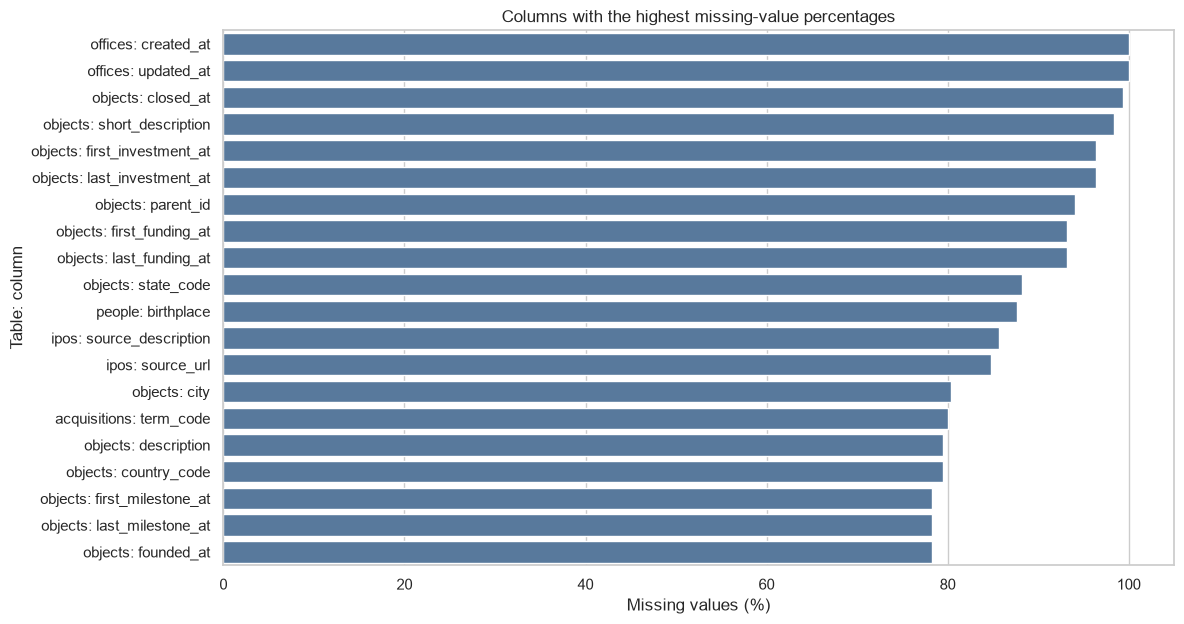

Highest column-level missingness: offices.csv / created_at (100.00%).


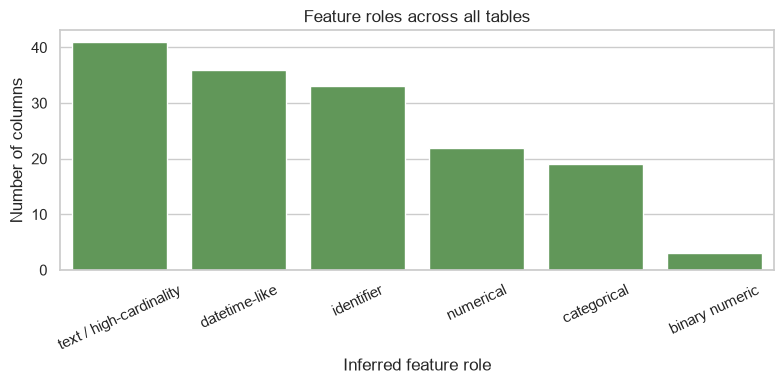

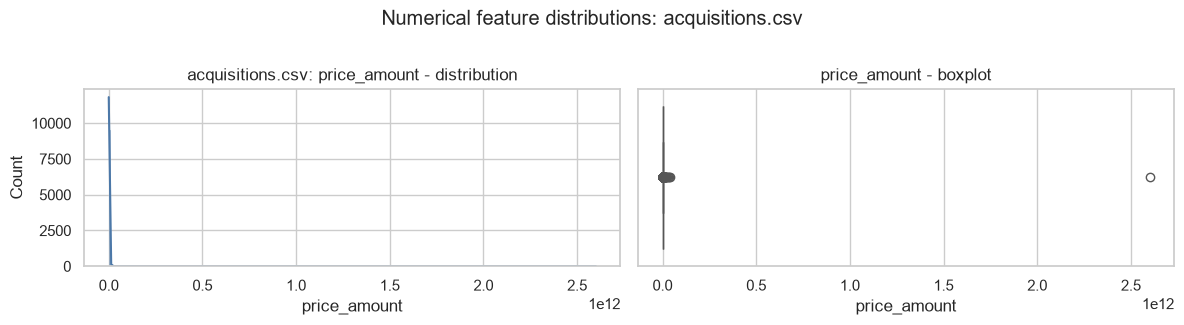

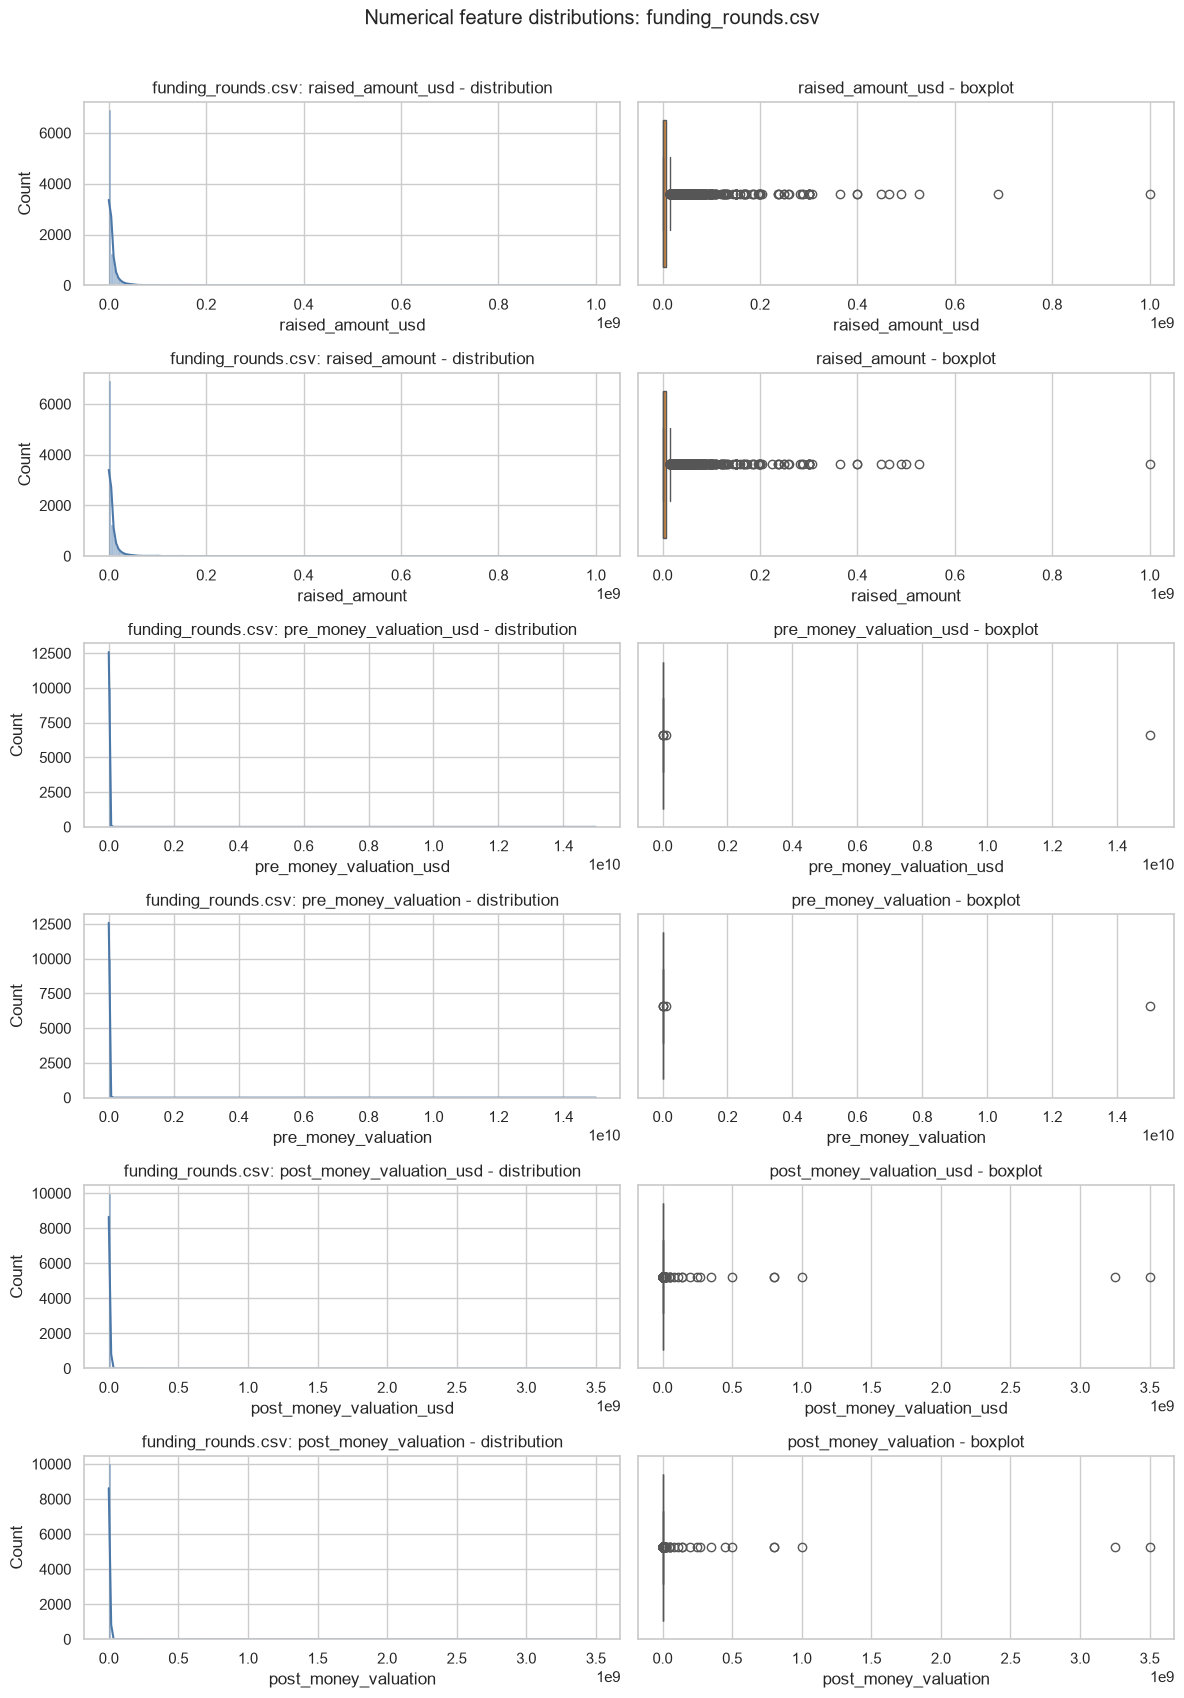

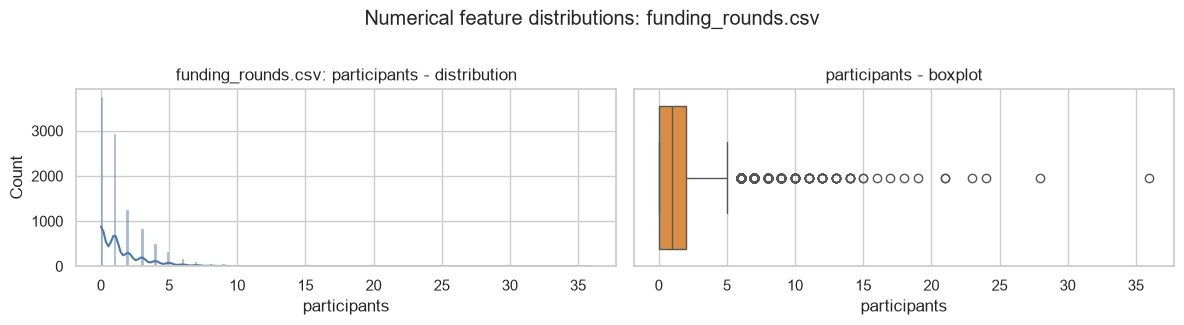

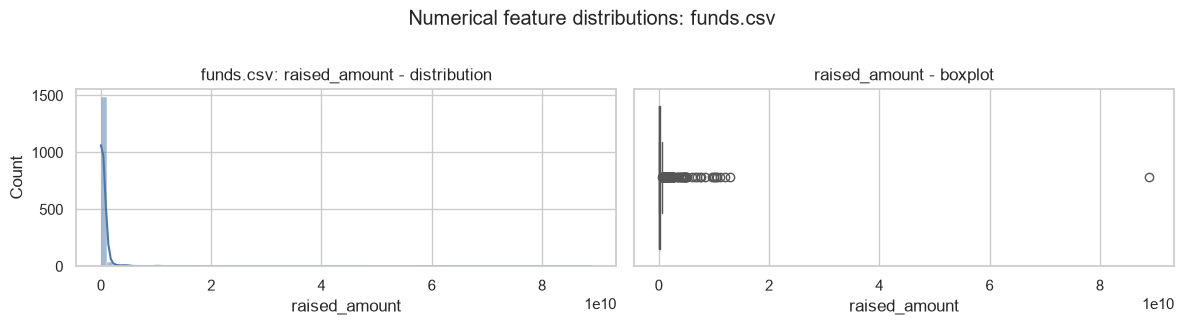

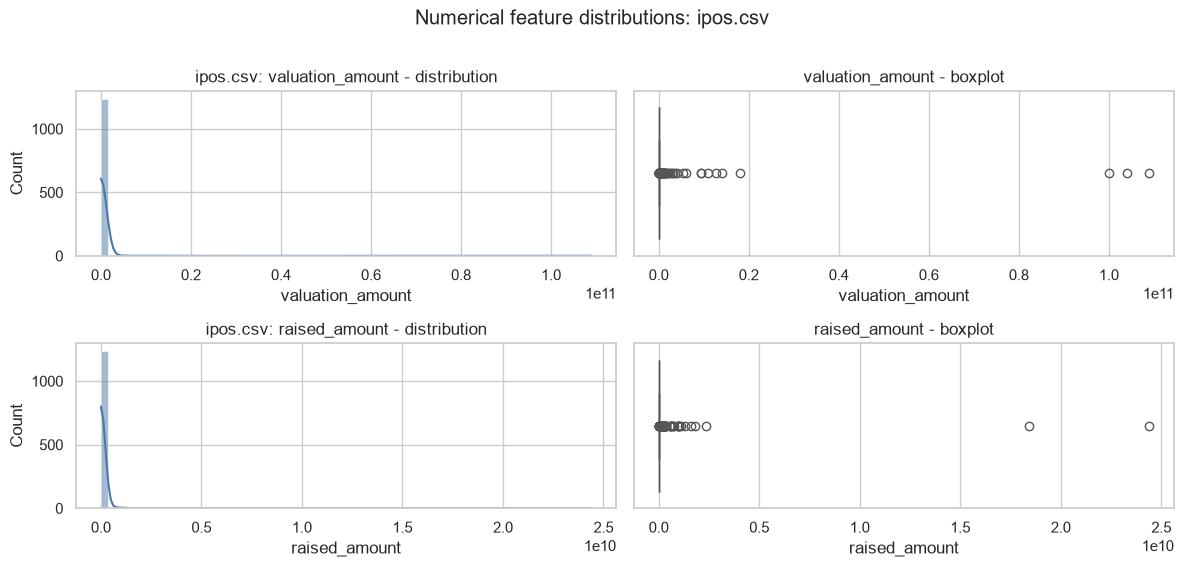

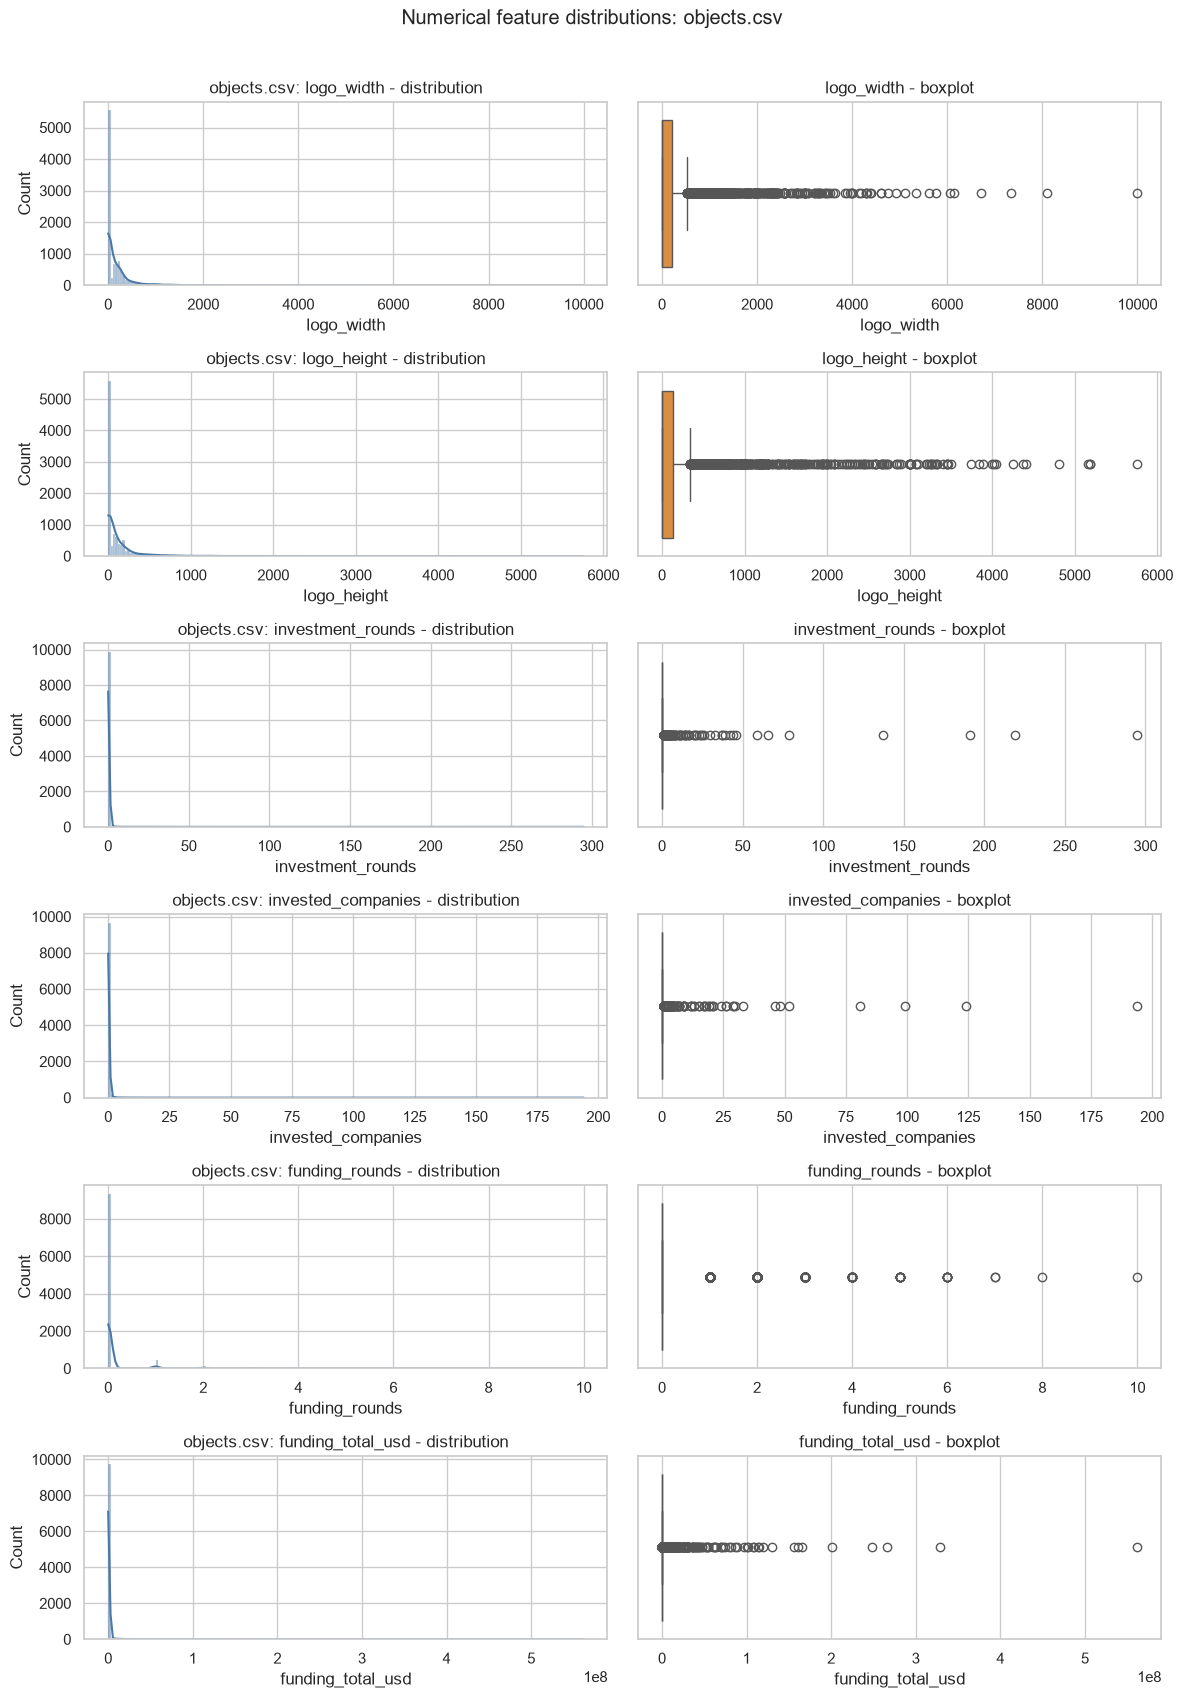

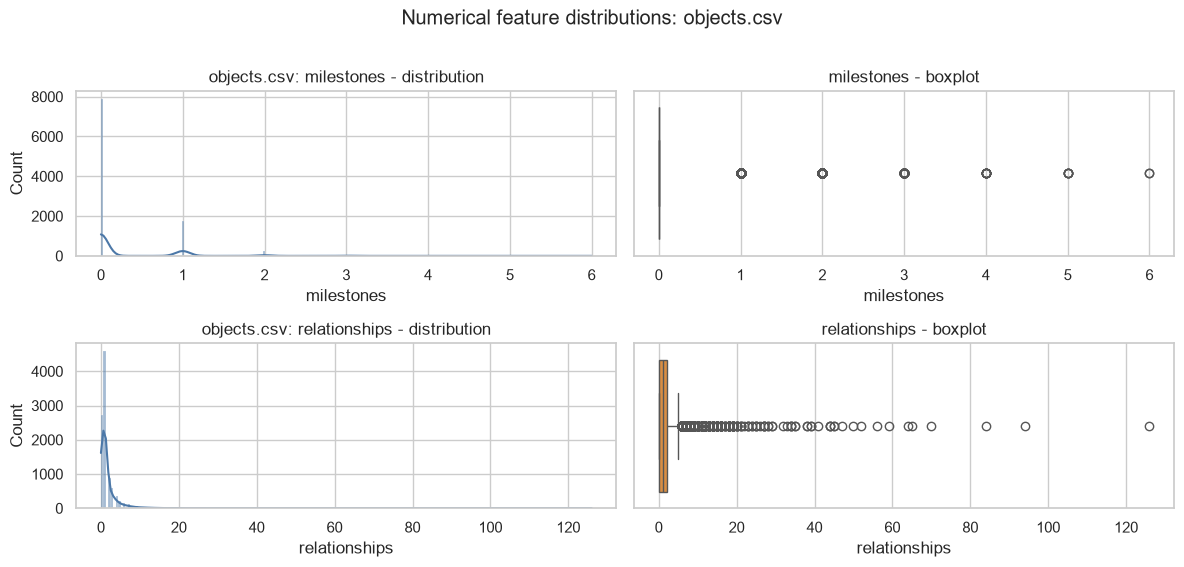

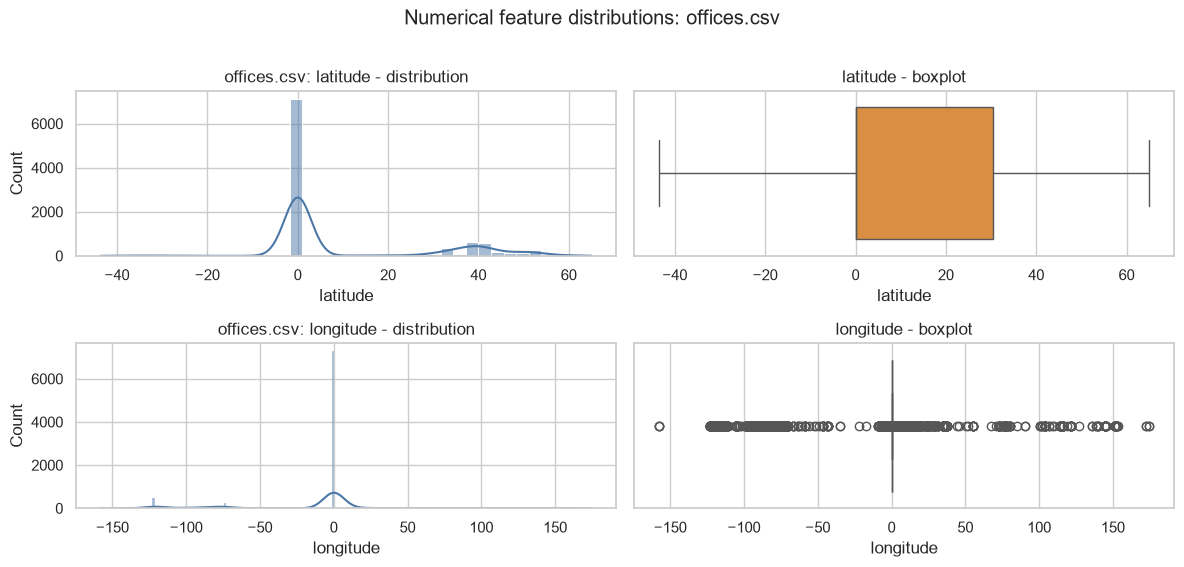

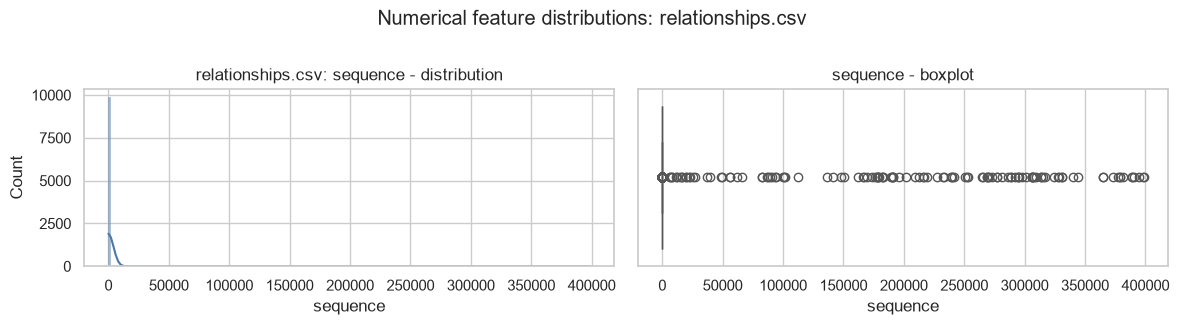

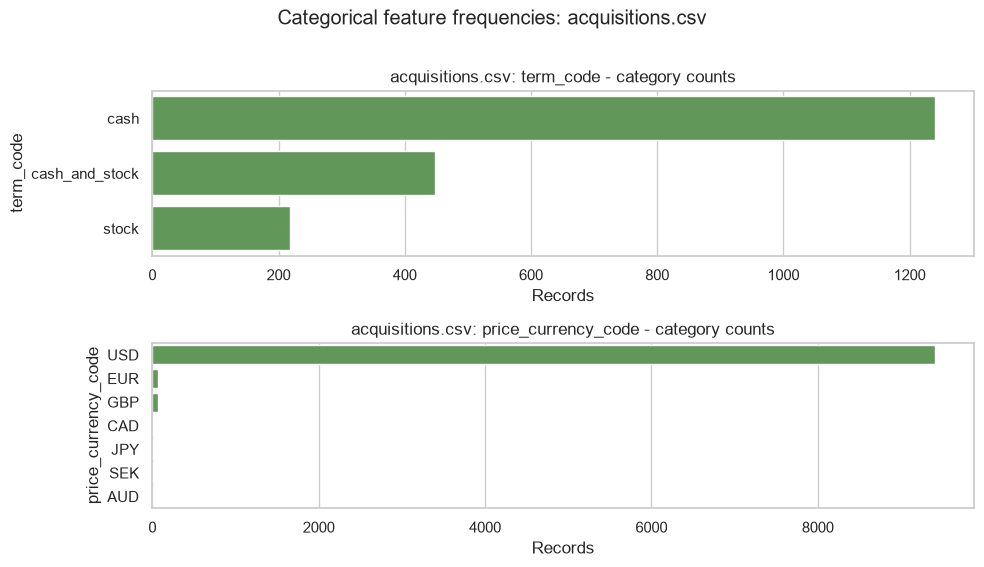

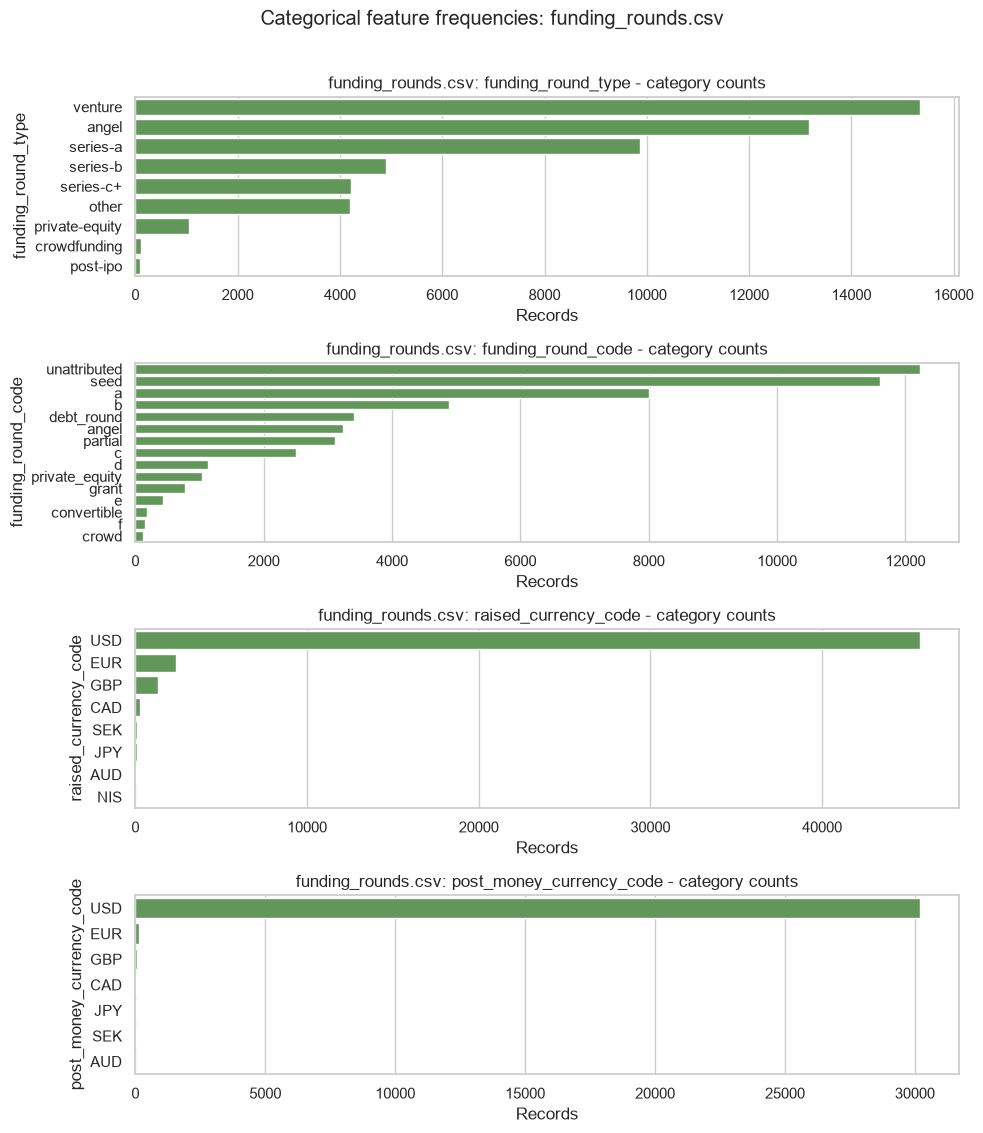

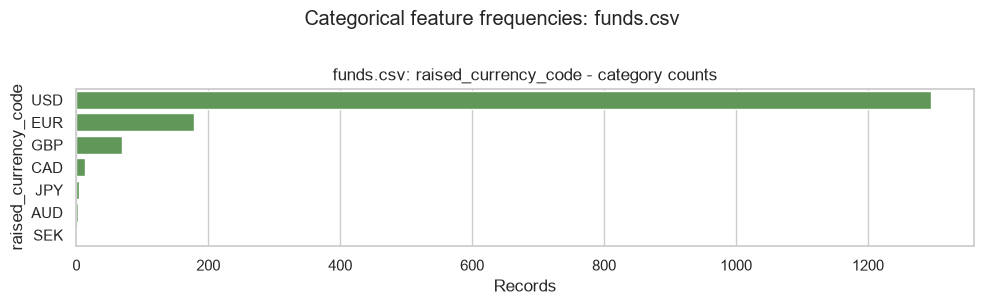

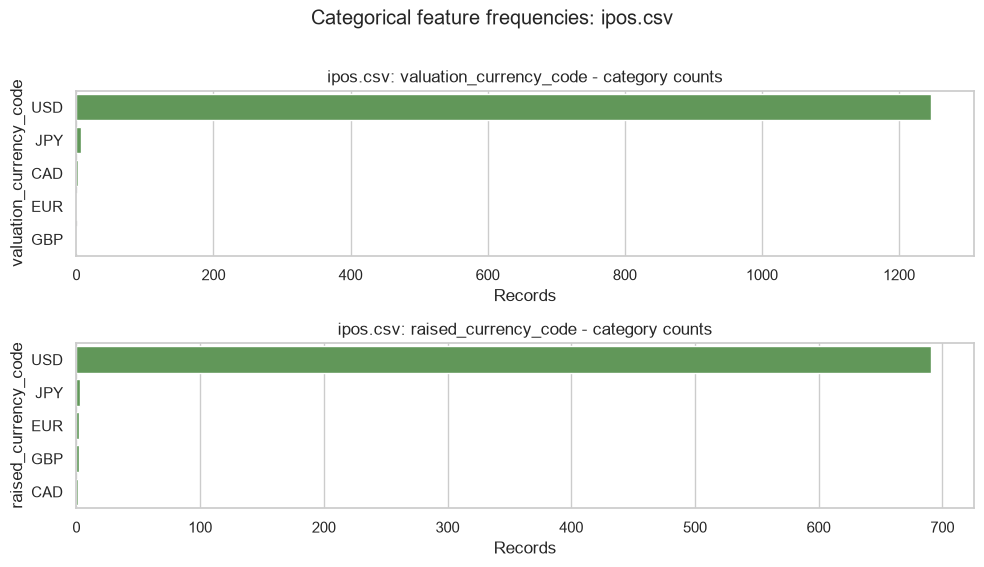

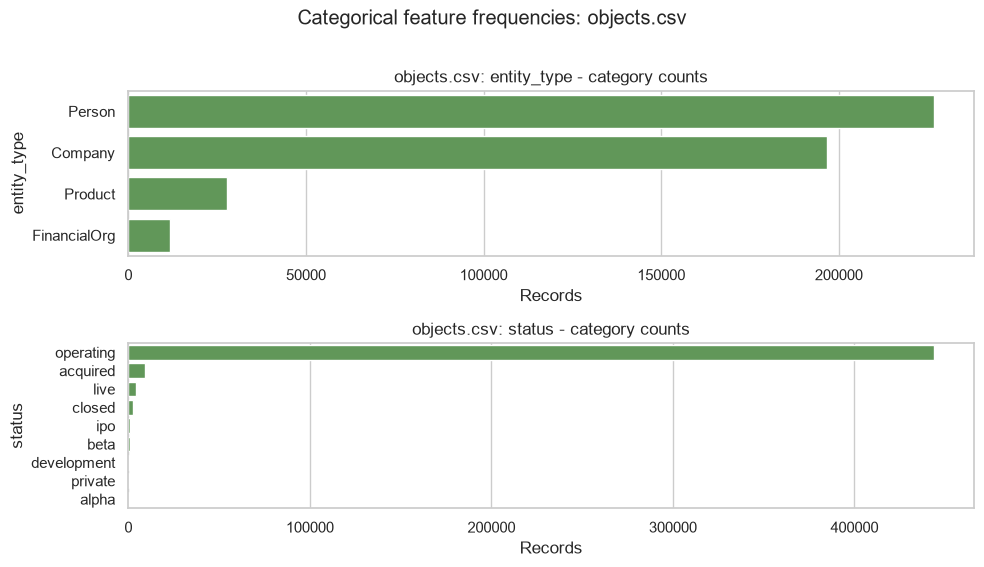

Interpret category plots alongside their full frequency counts; small categories may reflect rare events or incomplete reporting, not invalid records.


In [23]:
# Overview charts: missingness in the most incomplete columns and feature-role counts.
missing_plot = missing_summary.head(20).copy()
if not missing_plot.empty:
    missing_plot["feature"] = missing_plot["table"].str.replace(".csv", "", regex=False) + ": " + missing_plot["column"].astype(str)
    fig, ax = plt.subplots(figsize=(12, max(5, 0.32 * len(missing_plot))))
    sns.barplot(data=missing_plot, x="missing_pct", y="feature", color="#4C78A8", ax=ax)
    ax.set(title="Columns with the highest missing-value percentages", xlabel="Missing values (%)", ylabel="Table: column")
    plt.tight_layout(); plt.show()
    highest_missing = missing_plot.iloc[0]
    print(f"Highest column-level missingness: {highest_missing['table']} / {highest_missing['column']} ({highest_missing['missing_pct']:.2f}%).")
else:
    print("No missing values were found in the loaded tables.")

role_counts = column_profile.groupby("role").size().sort_values(ascending=False).rename("columns").reset_index()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=role_counts, x="role", y="columns", color="#59A14F", ax=ax)
ax.set(title="Feature roles across all tables", xlabel="Inferred feature role", ylabel="Number of columns")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

# Numerical distributions and boxplots, grouped into readable pages of at most six variables.
for table_name, frame in analysis_frames.items():
    columns = [c for c in frame.columns if _eda_role(c, frame[c]) == "numerical"]
    for start in range(0, len(columns), 6):
        page_columns = columns[start:start + 6]
        fig, axes = plt.subplots(len(page_columns), 2, figsize=(12, max(3.2, 2.8 * len(page_columns))), squeeze=False)
        for row_index, column in enumerate(page_columns):
            values = pd.to_numeric(frame[column], errors="coerce").dropna()
            plotted = values if len(values) <= 10000 else values.sample(10000, random_state=42)
            sns.histplot(plotted, bins="auto", kde=plotted.nunique() > 2, ax=axes[row_index, 0], color="#4C78A8")
            axes[row_index, 0].set(title=f"{table_name}: {column} - distribution", xlabel=column, ylabel="Count")
            plotted = values if len(values) <= 10000 else values.sample(10000, random_state=42)
            sns.boxplot(x=plotted, ax=axes[row_index, 1], color="#F28E2B", showfliers=True)
            axes[row_index, 1].set(title=f"{column} - boxplot", xlabel=column, ylabel="")
        fig.suptitle(f"Numerical feature distributions: {table_name}", y=1.01)
        plt.tight_layout(); plt.show()

# Categorical frequencies for low/moderate-cardinality fields only.
for table_name, frame in analysis_frames.items():
    columns = [c for c in frame.columns if _eda_role(c, frame[c]) == "categorical" and 2 <= frame[c].nunique(dropna=True) <= 20]
    for start in range(0, len(columns), 6):
        page_columns = columns[start:start + 6]
        fig, axes = plt.subplots(len(page_columns), 1, figsize=(10, max(3.0, 2.8 * len(page_columns))), squeeze=False)
        for row_index, column in enumerate(page_columns):
            counts = frame[column].value_counts(dropna=False).head(15).rename_axis("category").reset_index(name="count")
            counts["category"] = counts["category"].astype(str)
            sns.barplot(data=counts, x="count", y="category", color="#59A14F", ax=axes[row_index, 0])
            axes[row_index, 0].set(title=f"{table_name}: {column} - category counts", xlabel="Records", ylabel=column)
        fig.suptitle(f"Categorical feature frequencies: {table_name}", y=1.01)
        plt.tight_layout(); plt.show()
print("Interpret category plots alongside their full frequency counts; small categories may reflect rare events or incomplete reporting, not invalid records.")


## 8. Correlation analysis

Correlations use non-identifier numerical fields within each table. Associations are not causal evidence.


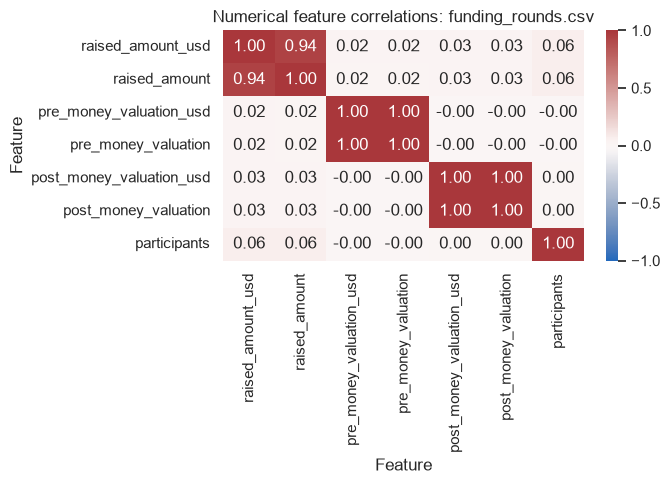

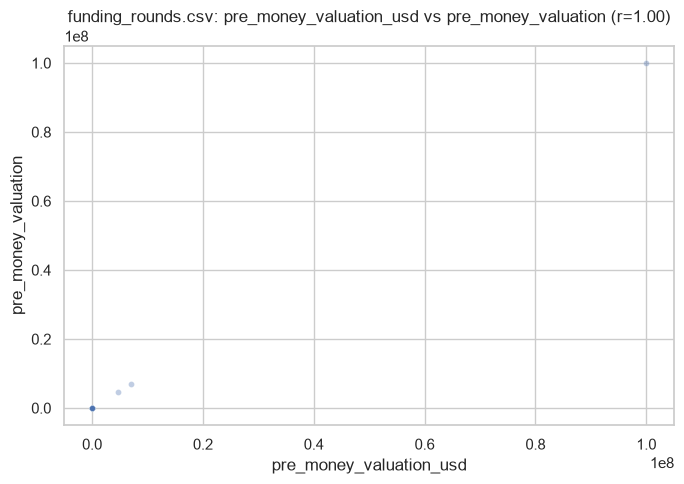

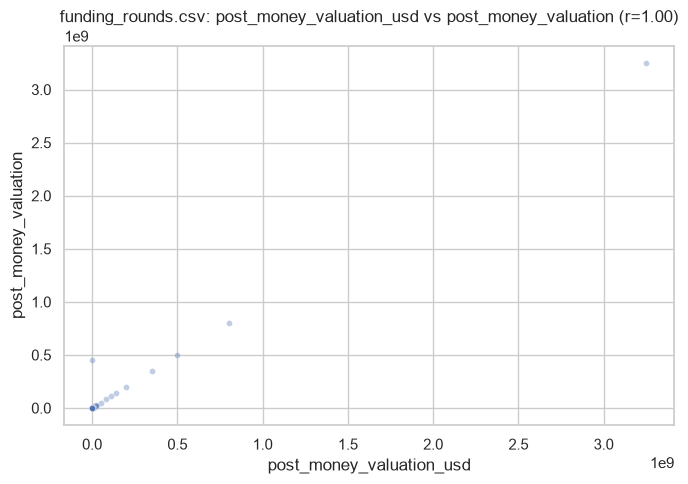

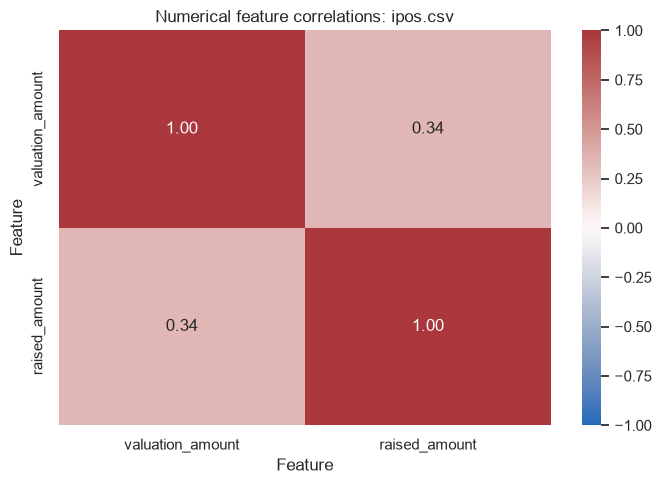

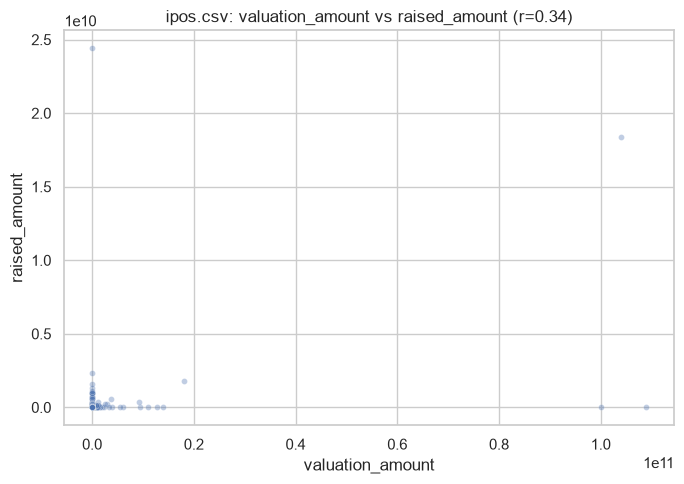

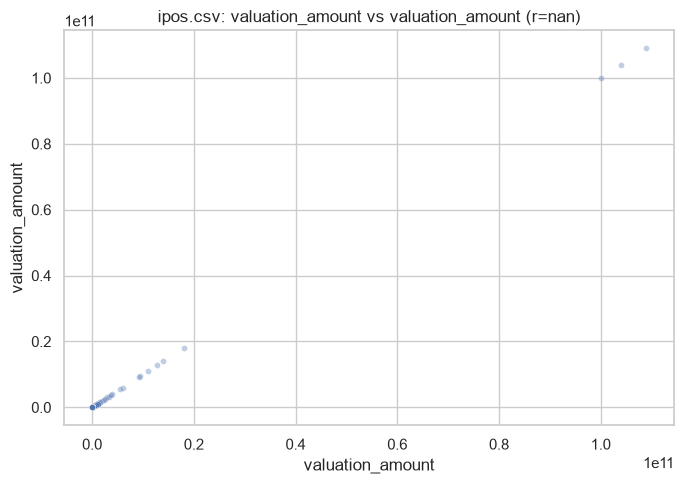

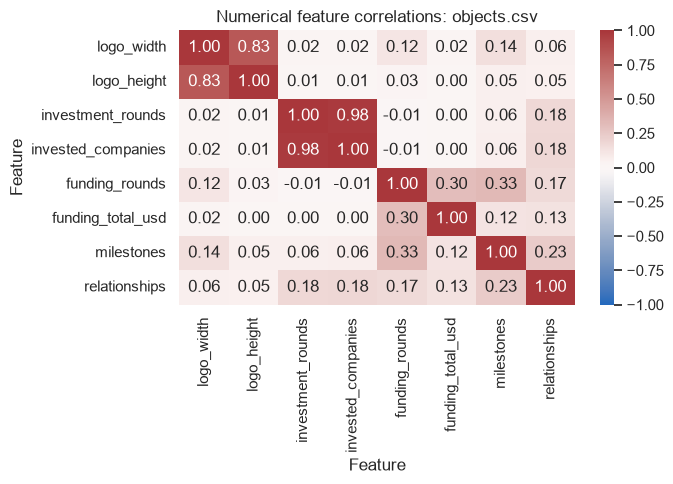

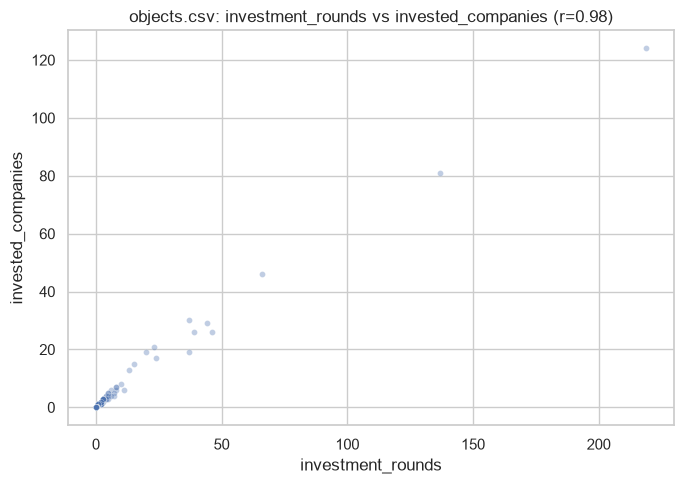

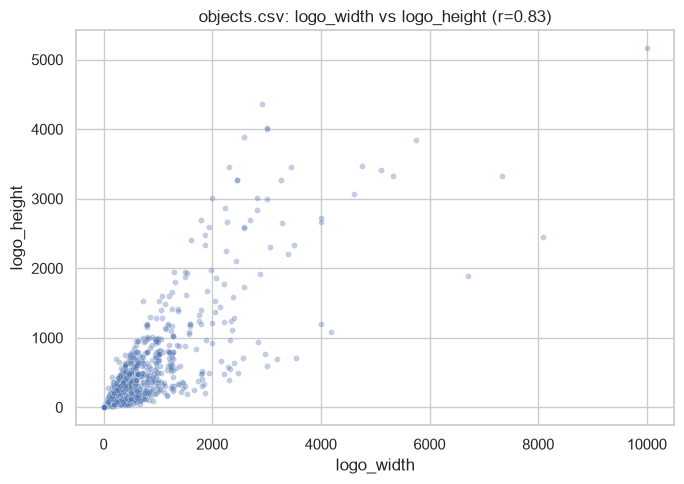

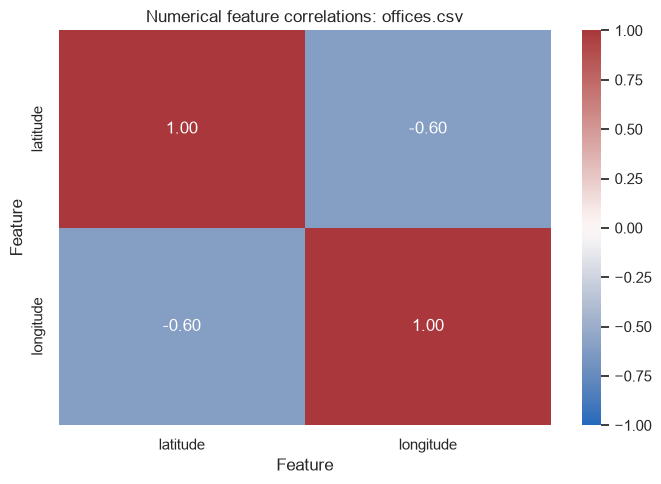

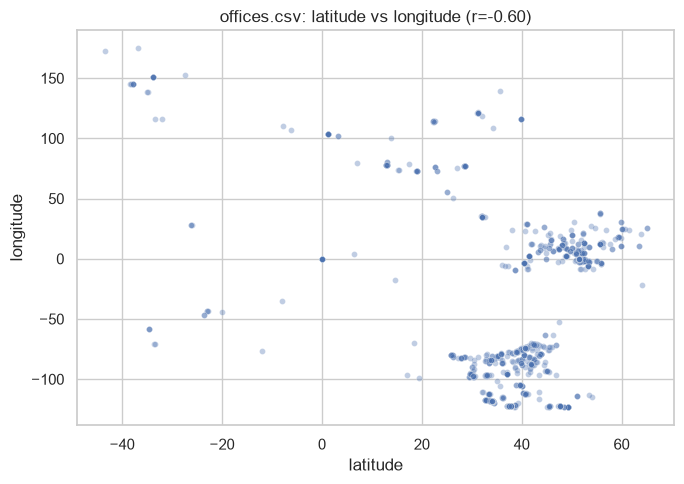

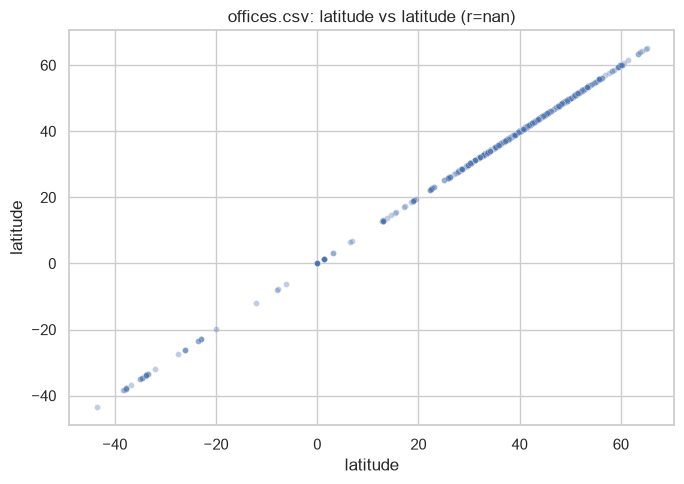

Strongest within-table numerical correlations:


,feature_1,feature_2,correlation,table
17,pre_money_valuation_usd,pre_money_valuation,1.0000,funding_rounds.csv
33,post_money_valuation_usd,post_money_valuation,0.9995,funding_rounds.csv
72,investment_rounds,invested_companies,0.9816,objects.csv
1,raised_amount_usd,raised_amount,0.9381,funding_rounds.csv
54,logo_width,logo_height,0.8290,objects.csv
118,latitude,longitude,-0.6041,offices.csv
50,valuation_amount,raised_amount,0.3402,ipos.csv
91,funding_rounds,milestones,0.3304,objects.csv
90,funding_rounds,funding_total_usd,0.3049,objects.csv
108,milestones,relationships,0.2344,objects.csv


In [24]:
correlation_tables = {}
correlation_pairs = []
for table_name, frame in analysis_frames.items():
    columns = [c for c in frame.columns if _eda_role(c, frame[c]) == "numerical"]
    if len(columns) < 2:
        continue
    numeric_data = frame[columns].apply(pd.to_numeric, errors="coerce")
    corr = numeric_data.corr(min_periods=20)
    correlation_tables[table_name] = corr
    fig, ax = plt.subplots(figsize=(max(7, 0.65 * len(columns)), max(5, 0.55 * len(columns))))
    sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, annot=len(columns) <= 8, fmt=".2f", ax=ax)
    ax.set(title=f"Numerical feature correlations: {table_name}", xlabel="Feature", ylabel="Feature")
    plt.tight_layout(); plt.show()

    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    pairs = upper.stack().rename("correlation").reset_index()
    if not pairs.empty:
        pairs.columns = ["feature_1", "feature_2", "correlation"]
        pairs["table"] = table_name
        correlation_pairs.append(pairs)
        strongest = pairs.reindex(pairs["correlation"].abs().sort_values(ascending=False).index).head(2)
        plot_sample = numeric_data.sample(min(len(numeric_data), 5000), random_state=42) if len(numeric_data) > 5000 else numeric_data
        for _, pair in strongest.iterrows():
            fig, ax = plt.subplots(figsize=(7, 5))
            sns.scatterplot(data=plot_sample, x=pair["feature_1"], y=pair["feature_2"], alpha=0.35, s=18, ax=ax)
            ax.set(title=f"{table_name}: {pair['feature_1']} vs {pair['feature_2']} (r={pair['correlation']:.2f})", xlabel=pair["feature_1"], ylabel=pair["feature_2"])
            plt.tight_layout(); plt.show()

all_correlation_pairs = pd.concat(correlation_pairs, ignore_index=True) if correlation_pairs else pd.DataFrame(columns=["feature_1", "feature_2", "correlation", "table"])
if not all_correlation_pairs.empty:
    strongest_correlations = all_correlation_pairs.assign(abs_correlation=lambda x: x["correlation"].abs()).sort_values("abs_correlation", ascending=False)
    print("Strongest within-table numerical correlations:")
    display(strongest_correlations.head(20).drop(columns="abs_correlation").round(4))
else:
    strongest_correlations = pd.DataFrame()
    print("No tables contained at least two usable numerical features for correlation analysis.")


## 9. Outlier analysis

IQR and Z-score flags are screening aids. No observations are capped, removed, or transformed.


Potential IQR outliers by numerical feature:


,table,column,observations,min,max,iqr_lower_bound,iqr_upper_bound,iqr_outlier_count,iqr_outlier_pct,zscore_gt_3_count,zscore_gt_3_pct
0,objects.csv,milestones,462651,0.0000,9.000000e+00,0.000000e+00,0.000000e+00,100358,21.6919,16769,3.6245
1,objects.csv,logo_height,462651,0.0000,9.600000e+03,-2.085000e+02,3.475000e+02,42484,9.1827,7636,1.6505
2,objects.csv,logo_width,462651,0.0000,1.820000e+04,-3.240000e+02,5.400000e+02,38436,8.3078,9175,1.9831
3,relationships.csv,sequence,402878,1.0000,3.999460e+05,-2.000000e+00,6.000000e+00,37654,9.3463,4709,1.1688
4,offices.csv,longitude,112718,-159.4803,1.769163e+02,0.000000e+00,0.000000e+00,32368,28.7159,910,0.8073
5,objects.csv,funding_rounds,462651,0.0000,1.500000e+01,0.000000e+00,0.000000e+00,31707,6.8533,11173,2.4150
6,objects.csv,relationships,462651,0.0000,1.189000e+03,-3.000000e+00,5.000000e+00,30199,6.5274,2568,0.5551
7,objects.csv,funding_total_usd,462651,0.0000,5.700000e+09,0.000000e+00,0.000000e+00,27874,6.0248,1629,0.3521
8,objects.csv,investment_rounds,462651,0.0000,5.290000e+02,0.000000e+00,0.000000e+00,16986,3.6714,1208,0.2611
9,objects.csv,invested_companies,462651,0.0000,4.590000e+02,0.000000e+00,0.000000e+00,16986,3.6714,1490,0.3221


Up to five flagged example rows per feature:


,table,column,row_index,value,iqr_lower_bound,iqr_upper_bound
0,acquisitions.csv,price_amount,0,20000000.0,-750000.0,1250000.0
1,acquisitions.csv,price_amount,1,60000000.0,-750000.0,1250000.0
2,acquisitions.csv,price_amount,2,280000000.0,-750000.0,1250000.0
3,acquisitions.csv,price_amount,3,100000000.0,-750000.0,1250000.0
4,acquisitions.csv,price_amount,4,25000000.0,-750000.0,1250000.0
...,...,...,...,...,...,...
100,relationships.csv,sequence,0,8.0,-2.0,6.0
101,relationships.csv,sequence,1,279242.0,-2.0,6.0
102,relationships.csv,sequence,15,8.0,-2.0,6.0
103,relationships.csv,sequence,20,8.0,-2.0,6.0


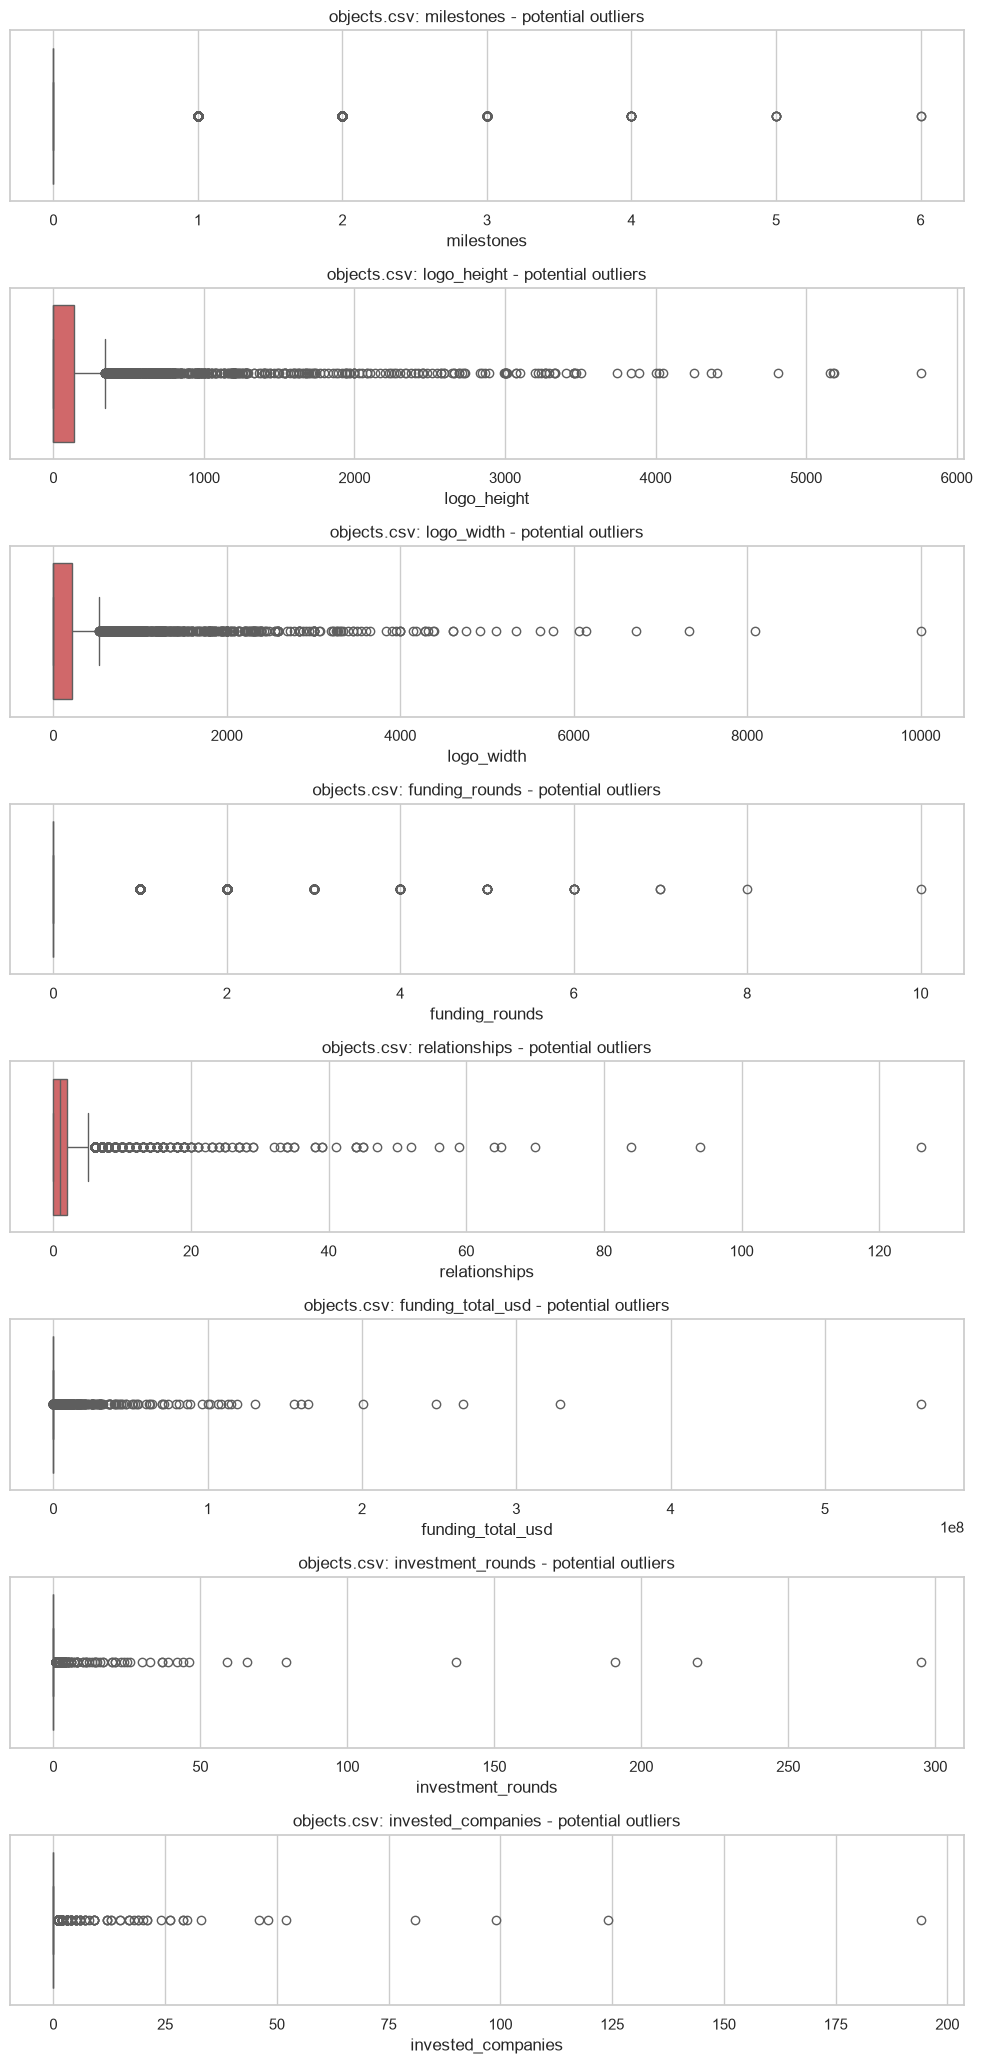

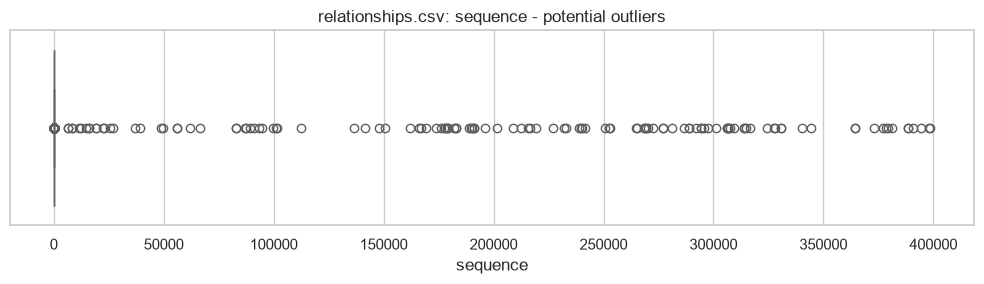

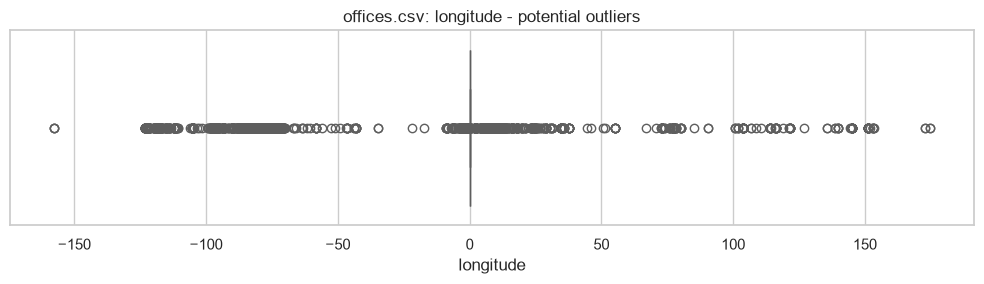

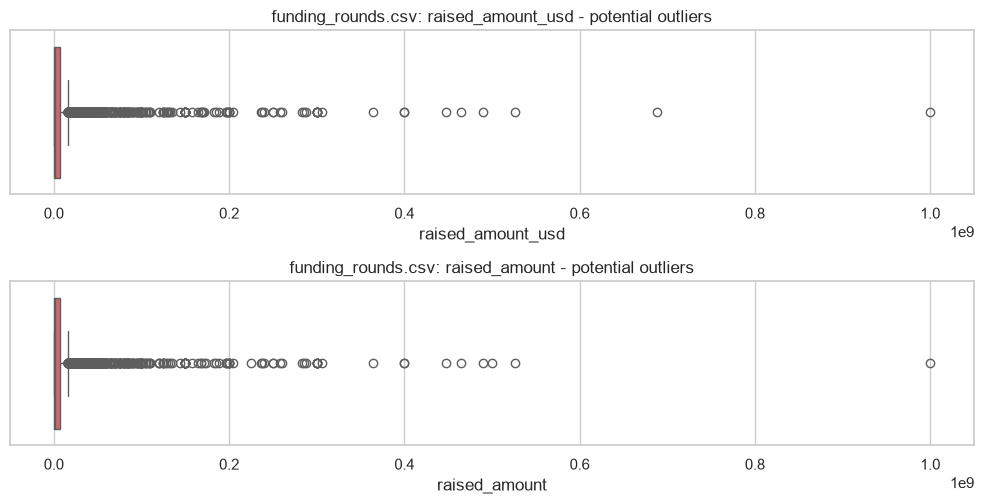

In [25]:
outlier_rows = []
outlier_sample_rows = []
for table_name, frame in analysis_frames.items():
    for column in frame.columns:
        if _eda_role(column, frame[column]) != "numerical":
            continue
        values = pd.to_numeric(frame[column], errors="coerce").dropna()
        if values.empty:
            continue
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        iqr_mask = (values < lower_bound) | (values > upper_bound)
        std = values.std(ddof=0)
        z_mask = ((values - values.mean()).abs() / std > 3) if std and np.isfinite(std) else pd.Series(False, index=values.index)
        outlier_rows.append({
            "table": table_name, "column": column, "observations": len(values),
            "min": values.min(), "max": values.max(), "iqr_lower_bound": lower_bound,
            "iqr_upper_bound": upper_bound, "iqr_outlier_count": int(iqr_mask.sum()),
            "iqr_outlier_pct": float(iqr_mask.mean() * 100),
            "zscore_gt_3_count": int(z_mask.sum()), "zscore_gt_3_pct": float(z_mask.mean() * 100)
        })
        for row_index, value in values[iqr_mask].head(5).items():
            outlier_sample_rows.append({
                "table": table_name, "column": column, "row_index": row_index,
                "value": value, "iqr_lower_bound": lower_bound, "iqr_upper_bound": upper_bound
            })
outlier_summary = pd.DataFrame(outlier_rows)
if not outlier_summary.empty:
    outlier_summary = outlier_summary.sort_values(["iqr_outlier_count", "iqr_outlier_pct"], ascending=False).reset_index(drop=True)
outlier_samples = pd.DataFrame(outlier_sample_rows, columns=["table", "column", "row_index", "value", "iqr_lower_bound", "iqr_upper_bound"])
print("Potential IQR outliers by numerical feature:")
display(outlier_summary.round(4))
print("Up to five flagged example rows per feature:")
display(outlier_samples)

# Visualize the most outlier-prone numerical fields; the full table above covers every numerical feature.
plot_outliers = outlier_summary[outlier_summary["iqr_outlier_count"] > 0].head(12)
for table_name in plot_outliers["table"].drop_duplicates():
    frame = analysis_frames[table_name]
    selected = plot_outliers.loc[plot_outliers["table"] == table_name, "column"].tolist()
    fig, axes = plt.subplots(len(selected), 1, figsize=(10, max(3, 2.6 * len(selected))), squeeze=False)
    for i, column in enumerate(selected):
        values = pd.to_numeric(frame[column], errors="coerce").dropna()
        plotted = values if len(values) <= 10000 else values.sample(10000, random_state=42)
        sns.boxplot(x=plotted, ax=axes[i, 0], color="#E15759", showfliers=True)
        axes[i, 0].set(title=f"{table_name}: {column} - potential outliers", xlabel=column, ylabel="")
    plt.tight_layout(); plt.show()


## 10. Model readiness and key findings

No target or model is assumed. Company status is a candidate label only; prediction timing and feature availability need validation.


Company records: 196,553; status is a candidate label only, not an assumed target.


,status,count,percent
0,operating,183441,93.33
1,acquired,9394,4.78
2,closed,2584,1.31
3,ipo,1134,0.58


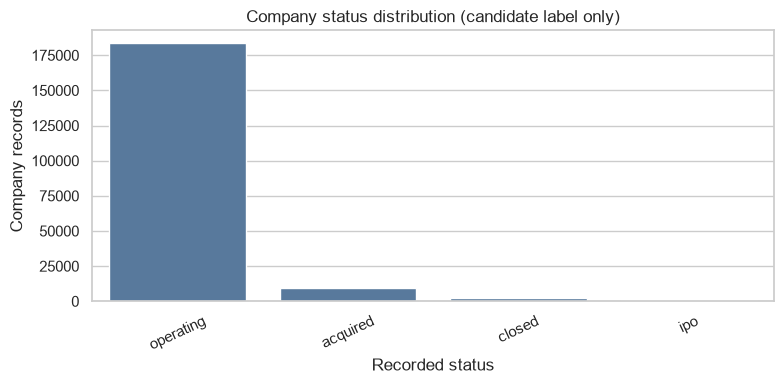

Company status percentages within the top categories of each categorical field (candidate-label exploration):

category_code


status,acquired,closed,ipo,operating
category_code,,,,
advertising,5.12,1.56,0.39,92.93
biotech,10.27,2.64,5.58,81.51
consulting,2.72,0.62,0.42,96.24
ecommerce,2.99,1.78,0.28,94.96
enterprise,9.21,1.53,1.22,88.04
games_video,4.55,2.67,0.41,92.37
mobile,6.06,2.51,0.71,90.72
other,2.30,0.76,0.54,96.41
software,8.18,1.75,0.64,89.43


Readiness assessment:
- Target: none has been selected. If the goal is classification, confirm whether recorded company status is appropriate and define the prediction date.
- Inputs: company attributes can be candidates, but relational tables need explicit entity-level joins/aggregations and their grain must be preserved.
- Leakage: for status/outcome prediction, close/IPO/acquisition dates, status itself, later funding rounds, milestones, and snapshot aggregates may reveal future information; exclude or time-bound them relative to a prediction cutoff.
- Preprocessing: parse date-like columns into datetime features; impute missing values inside train-only pipelines; encode categorical variables; scale numeric features for scale-sensitive models; preserve indicators for structurally missing fields where appropriate.
- Class balance: inspect the candidate status counts above; if a target is later approved, use stratified evaluation and class-aware metrics rather than accuracy alone.
- V

In [26]:
company_frame = None
company_status = pd.Series(dtype="int64")
objects_frame = analysis_frames.get("objects.csv")
if objects_frame is not None and {"entity_type", "status"}.issubset(objects_frame.columns):
    company_frame = objects_frame.loc[objects_frame["entity_type"].astype("string").str.casefold().eq("company")].copy()
    company_status = company_frame["status"].value_counts(dropna=False)
    status_table = company_status.rename_axis("status").reset_index(name="count")
    status_table["percent"] = (status_table["count"] / max(len(company_frame), 1) * 100).round(2)
    print(f"Company records: {len(company_frame):,}; status is a candidate label only, not an assumed target.")
    display(status_table)
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(data=status_table, x="status", y="count", color="#4C78A8", ax=ax)
    ax.set(title="Company status distribution (candidate label only)", xlabel="Recorded status", ylabel="Company records")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout(); plt.show()
else:
    status_table = pd.DataFrame(columns=["status", "count", "percent"])
    print("A company status distribution was not computed because the required fields were not present.")

# These cross-tabs are exploratory views of a possible label, not a target assumption.
categorical_company_vs_status = {}
if company_frame is not None and not company_status.empty:
    candidate_features = [
        c for c in company_frame.columns
        if c != "status" and _eda_role(c, company_frame[c]) == "categorical"
        and 2 <= company_frame[c].nunique(dropna=True) <= 50
    ]
    for column in candidate_features:
        top_categories = company_frame[column].value_counts(dropna=True).head(10).index
        subset = company_frame.loc[company_frame[column].isin(top_categories), [column, "status"]]
        cross_tab = pd.crosstab(subset[column], subset["status"], normalize="index").mul(100).round(2)
        categorical_company_vs_status[column] = cross_tab
    if categorical_company_vs_status:
        print("Company status percentages within the top categories of each categorical field (candidate-label exploration):")
        for column, cross_tab in categorical_company_vs_status.items():
            print(f"\n{column}")
            display(cross_tab)

print("Readiness assessment:")
readiness_points = [
    "Target: none has been selected. If the goal is classification, confirm whether recorded company status is appropriate and define the prediction date.",
    "Inputs: company attributes can be candidates, but relational tables need explicit entity-level joins/aggregations and their grain must be preserved.",
    "Leakage: for status/outcome prediction, close/IPO/acquisition dates, status itself, later funding rounds, milestones, and snapshot aggregates may reveal future information; exclude or time-bound them relative to a prediction cutoff.",
    "Preprocessing: parse date-like columns into datetime features; impute missing values inside train-only pipelines; encode categorical variables; scale numeric features for scale-sensitive models; preserve indicators for structurally missing fields where appropriate.",
    "Class balance: inspect the candidate status counts above; if a target is later approved, use stratified evaluation and class-aware metrics rather than accuracy alone.",
    "Validation: split by time and/or company where the task requires future generalization; avoid leakage across joined rows for the same entity.",
    "No automatic cleaning: missing values, duplicate-key candidates, category anomalies, and outliers remain unmodified pending domain review."
]
for point in readiness_points:
    print("- " + point)


In [27]:
total_rows = int(dataset_overview["rows"].sum())
total_tables = len(dataset_overview)
total_columns = int(dataset_overview["columns"].sum())
exact_duplicates = int(dataset_overview["exact_duplicate_rows"].sum())
largest = dataset_overview.iloc[0]
highest_missing_table = dataset_overview.sort_values(
    "missing_cells_pct", ascending=False
).iloc[0]
nonempty_missing = missing_summary.loc[missing_summary["missing_pct"] < 100]
nonempty_missing = nonempty_missing.sort_values("missing_pct", ascending=False)
top_missing_feature = nonempty_missing.iloc[0] if not nonempty_missing.empty else None

company_category_text = "not available"
if company_frame is not None and "category_code" in company_frame.columns:
    category_counts = company_frame["category_code"].value_counts().head(5)
    company_category_text = ", ".join(
        f"{category} ({int(count):,})" for category, count in category_counts.items()
    )

funding_type_text = "not available"
funding_frame = analysis_frames.get("funding_rounds.csv")
if funding_frame is not None and "funding_round_type" in funding_frame.columns:
    funding_counts = funding_frame["funding_round_type"].value_counts().head(5)
    funding_type_text = ", ".join(
        f"{category} ({int(count):,})" for category, count in funding_counts.items()
    )

report_lines = [
    "# EDA Summary",
    "",
    "## Dataset",
    f"Reviewed {total_tables} related tables with {total_rows:,} total rows and {total_columns:,} fields across their schemas. Largest: `{largest['table']}` ({largest['rows']:,} rows). Exact duplicate rows: {exact_duplicates:,}.",
    "",
    "## Data quality",
    f"Highest table-level missingness: `{highest_missing_table['table']}` ({highest_missing_table['missing_cells_pct']:.2f}%).",
]
if top_missing_feature is not None:
    report_lines.append(
        f"Most incomplete partially observed field: `{top_missing_feature['table']} / {top_missing_feature['column']}` ({top_missing_feature['missing_pct']:.2f}%)."
    )
report_lines.extend([
    "",
    "## Company status",
    "Recorded status is an exploratory candidate label, not a confirmed future outcome.",
])
if not status_table.empty:
    status_counts_text = ", ".join(
        f"{row.status}: {int(row.count):,} ({row.percent:.2f}%)"
        for row in status_table.itertuples(index=False)
    )
    report_lines.append(f"Observed status counts: {status_counts_text}.")
report_lines.extend([
    f"Top company categories: {company_category_text}.",
    f"Top funding-round types: {funding_type_text}.",
    "",
    "## Feature patterns",
])
if not numeric_summary.empty:
    skewed = numeric_summary.assign(
        abs_skew=numeric_summary["skewness"].abs()
    ).sort_values("abs_skew", ascending=False).head(3)
    skew_text = "; ".join(
        f"{row['table']} / {row['column']} (skew={row['skewness']:.2f})"
        for _, row in skewed.iterrows()
    )
    report_lines.append(f"Largest absolute skewness values: {skew_text}.")
if not strongest_correlations.empty:
    strongest_row = strongest_correlations.iloc[0]
    report_lines.append(
        f"Strongest within-table correlation: `{strongest_row['table']}` - `"
        f"{strongest_row['feature_1']}` vs `{strongest_row['feature_2']}` "
        f"(r={strongest_row['correlation']:.3f}); association does not imply causation."
    )
if not outlier_summary.empty:
    top_outlier = outlier_summary.iloc[0]
    report_lines.append(
        f"Most IQR-flagged feature by count: `{top_outlier['table']} / "
        f"{top_outlier['column']}` ({int(top_outlier['iqr_outlier_count']):,} records, "
        f"{top_outlier['iqr_outlier_pct']:.2f}%). Review before treatment."
    )
report_lines.extend([
    "",
    "## Modeling readiness",
    "No target is confirmed. Preserve table grain and use documented joins; define the prediction cutoff and check feature timing for leakage. Fit preprocessing on training data only. No source values were changed or outliers removed.",
])
display(Markdown("\n".join(report_lines)))


# EDA Summary

## Dataset
Reviewed 11 related tables with 1,500,237 total rows and 154 fields across their schemas. Largest: `objects.csv` (462,651 rows). Exact duplicate rows: 0.

## Data quality
Highest table-level missingness: `objects.csv` (42.78%).
Most incomplete partially observed field: `objects.csv / closed_at` (99.39%).

## Company status
Recorded status is an exploratory candidate label, not a confirmed future outcome.
Observed status counts: operating: 183,441 (93.33%), acquired: 9,394 (4.78%), closed: 2,584 (1.31%), ipo: 1,134 (0.58%).
Top company categories: software (17,922), web (15,118), other (13,617), ecommerce (9,065), games_video (7,520).
Top funding-round types: venture (15,342), angel (13,163), series-a (9,873), series-b (4,892), series-c+ (4,216).

## Feature patterns
Largest absolute skewness values: funding_rounds.csv / pre_money_valuation (skew=228.84); funding_rounds.csv / pre_money_valuation_usd (skew=228.84); objects.csv / funding_total_usd (skew=147.41).
Strongest within-table correlation: `funding_rounds.csv` - `pre_money_valuation_usd` vs `pre_money_valuation` (r=1.000); association does not imply causation.
Most IQR-flagged feature by count: `objects.csv / milestones` (100,358 records, 21.69%). Review before treatment.

## Modeling readiness
No target is confirmed. Preserve table grain and use documented joins; define the prediction cutoff and check feature timing for leakage. Fit preprocessing on training data only. No source values were changed or outliers removed.